# Task 3 — Inference-time compute allocation

Abdullah Irfan · ATML PA3 · Analysis seed 6304

**Default: CPU report mode.** Run all cells to verify the saved evidence and display the results. No model is loaded. GPU reproduction is disabled unless explicitly enabled in the final cell.

Offline: MATH / Qwen2.5-3B and MathVista / Qwen2.5-VL-3B. Live: 50 fixed MATH questions, original pinned Qwen2.5-3B-Instruct in FP16.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata as metadata
from IPython.display import display, Markdown, Image

if Path('/content').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

override = os.environ.get('PA3_TASK3_REPORT_DIR')
candidates = ([Path(override)] if override else []) + [
    Path.cwd(), Path.cwd() / 'task3',
    Path('/content/drive/MyDrive/ATML/PA3/pa3_repo/task3'),
    Path('/content/drive/MyDrive/ATML/PA3/task3'),
]
TASK3 = next((p for p in candidates if (p / 'analysis/audit.json').is_file()), None)
assert TASK3 is not None, 'Set PA3_TASK3_REPORT_DIR to the finalized task3 folder.'
print('Task 3 saved-result report · CPU mode')


Mounted at /content/drive
Task 3 saved-result report · CPU mode


## Setup and isolation

Each offline dataset has 1,000 questions × 32 rollouts. Sort IDs lexicographically and permute with default_rng(6304): 200 development, 800 held-out. Ten seeded candidate orders are shared across methods and stopping rules, with nested budgets 1, 2, 4, 8, 16, 32. The first 50 MATH held-out IDs form the live subset. All candidate rollouts remain within their question.

The scorer was frozen before performance evaluation. Supplied extracted answers are used for offline scoring; only live responses use the balanced-brace last-box extractor. Missing answers remain in voting, costs and accuracy denominators. Candidate groups and all stopping inputs exclude gold and future candidates.

In [2]:
versions = json.loads((TASK3 / 'configs/scorer_frozen.json').read_text())['packages']
versions['matplotlib'] = '3.10.8'
missing = []
for name, version in versions.items():
    try:
        if metadata.version(name) != version:
            missing.append(f'{name}=={version}')
    except metadata.PackageNotFoundError:
        missing.append(f'{name}=={version}')
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', *missing], check=True)
print('Pinned CPU analysis dependencies ready.')


Pinned CPU analysis dependencies ready.


## Audit the recorded evidence

Recheck the frozen source/input identities, all saved offline chunks, splits and nested candidate orders, selected IDs, costs, development threshold selection and held-out metrics/intervals. Recheck every live call, seed, cap, EOS count, revision input, shared cost and final grade. This does not re-read raw parquet/NPZ/model tensor bytes; their original preparation hashes and audit receipts remain available.

In [3]:
subprocess.run([
    sys.executable, str(TASK3 / 'code/task3_analyze.py'),
    '--task-dir', str(TASK3),
], check=True)
audit = json.loads((TASK3 / 'analysis/audit.json').read_text())
assert audit['passed'] and not audit['gpu_used']
for check in audit['checks']:
    print('PASS:', check)


PASS: Frozen source and input identities
PASS: All 40 offline chunk hashes; 2000 questions and 64000 candidates
PASS: Saved splits, nested candidate orders, selected IDs and retained-token costs
PASS: Development-only adaptive grid selection and frozen thresholds
PASS: All held-out fixed/adaptive summaries and paired bootstrap intervals
PASS: All 250 live call hashes, prompt/seed/cap/EOS/revision/cost records
PASS: Live gold-free voting, frozen grading, paired intervals and revision transitions


## Sampling opportunity and selection errors

Oracle coverage asks whether any consumed candidate is correct. It is a retrospective upper bound. Self-consistency can miss a correct candidate when a wrong answer receives more votes. FirstAns consumes only one response even when compared at a larger available pool budget. Distinct groups include NO_ANSWER. The error decomposition is shown for self-consistency.

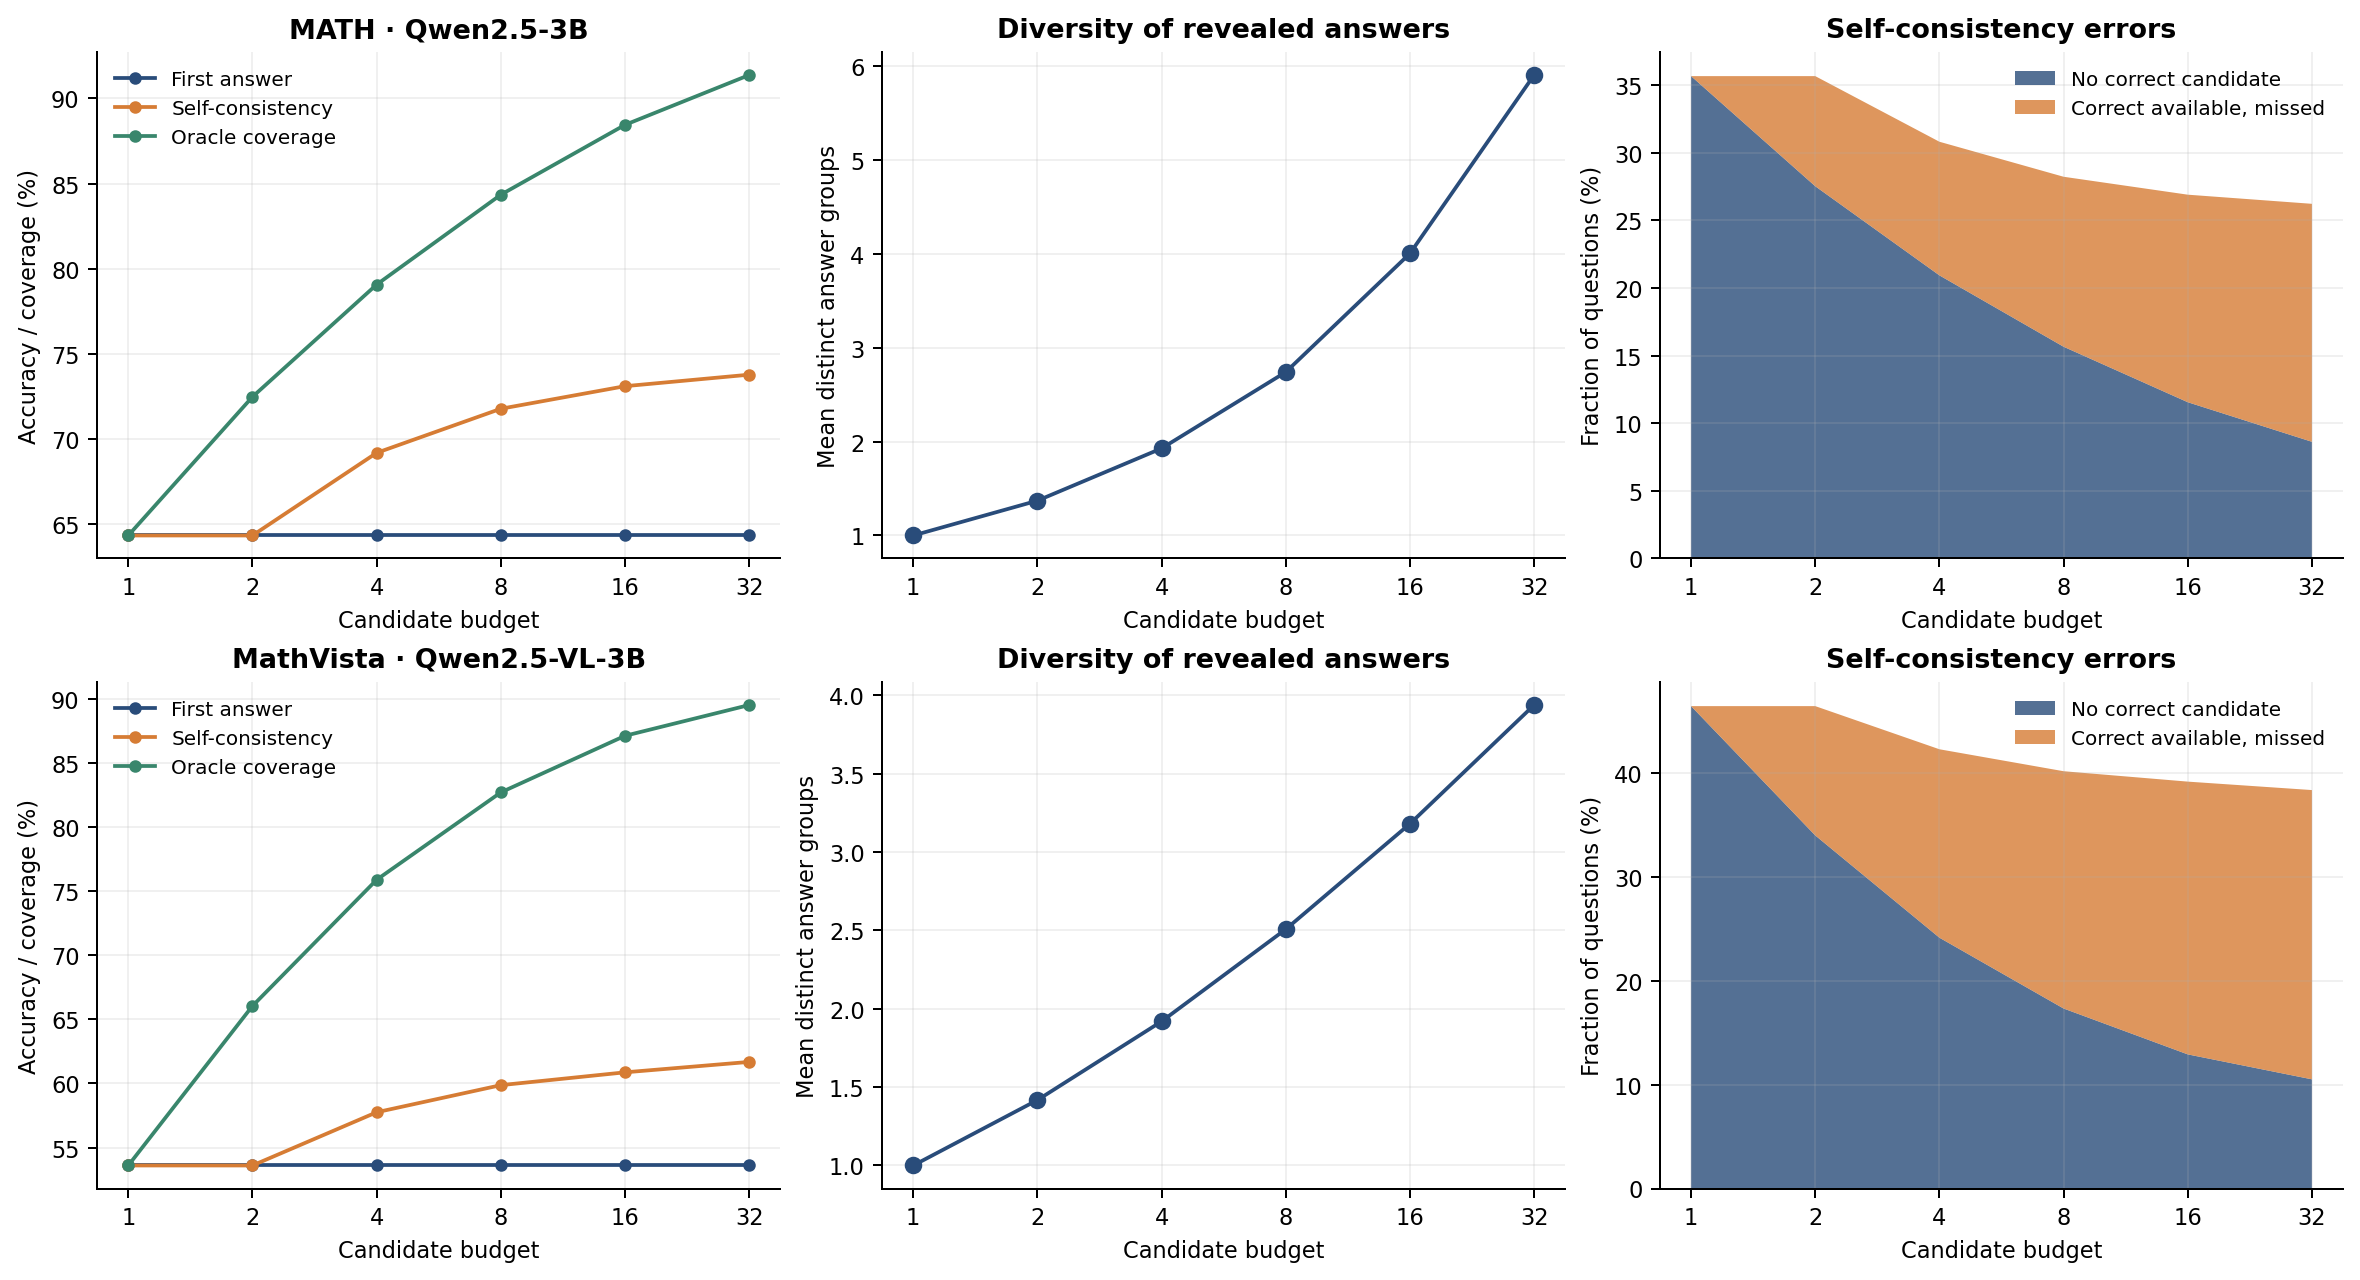

In [4]:
display(Image(filename=str(TASK3 / 'figures/sampling_selection.png')))

## Quality scores and aggregation

Mean sampled-token log-probability and mean KL(U∥p) are read from raw full-distribution measurements. Self-certainty is divergence from uniform, not a calibrated probability of correctness. RWC uses descending average ranks and weights (N−rank)/(N−1), with earliest-supporting-candidate ties. Shortest selection is a length control. All N=32 methods except FirstAns consume the same pool.

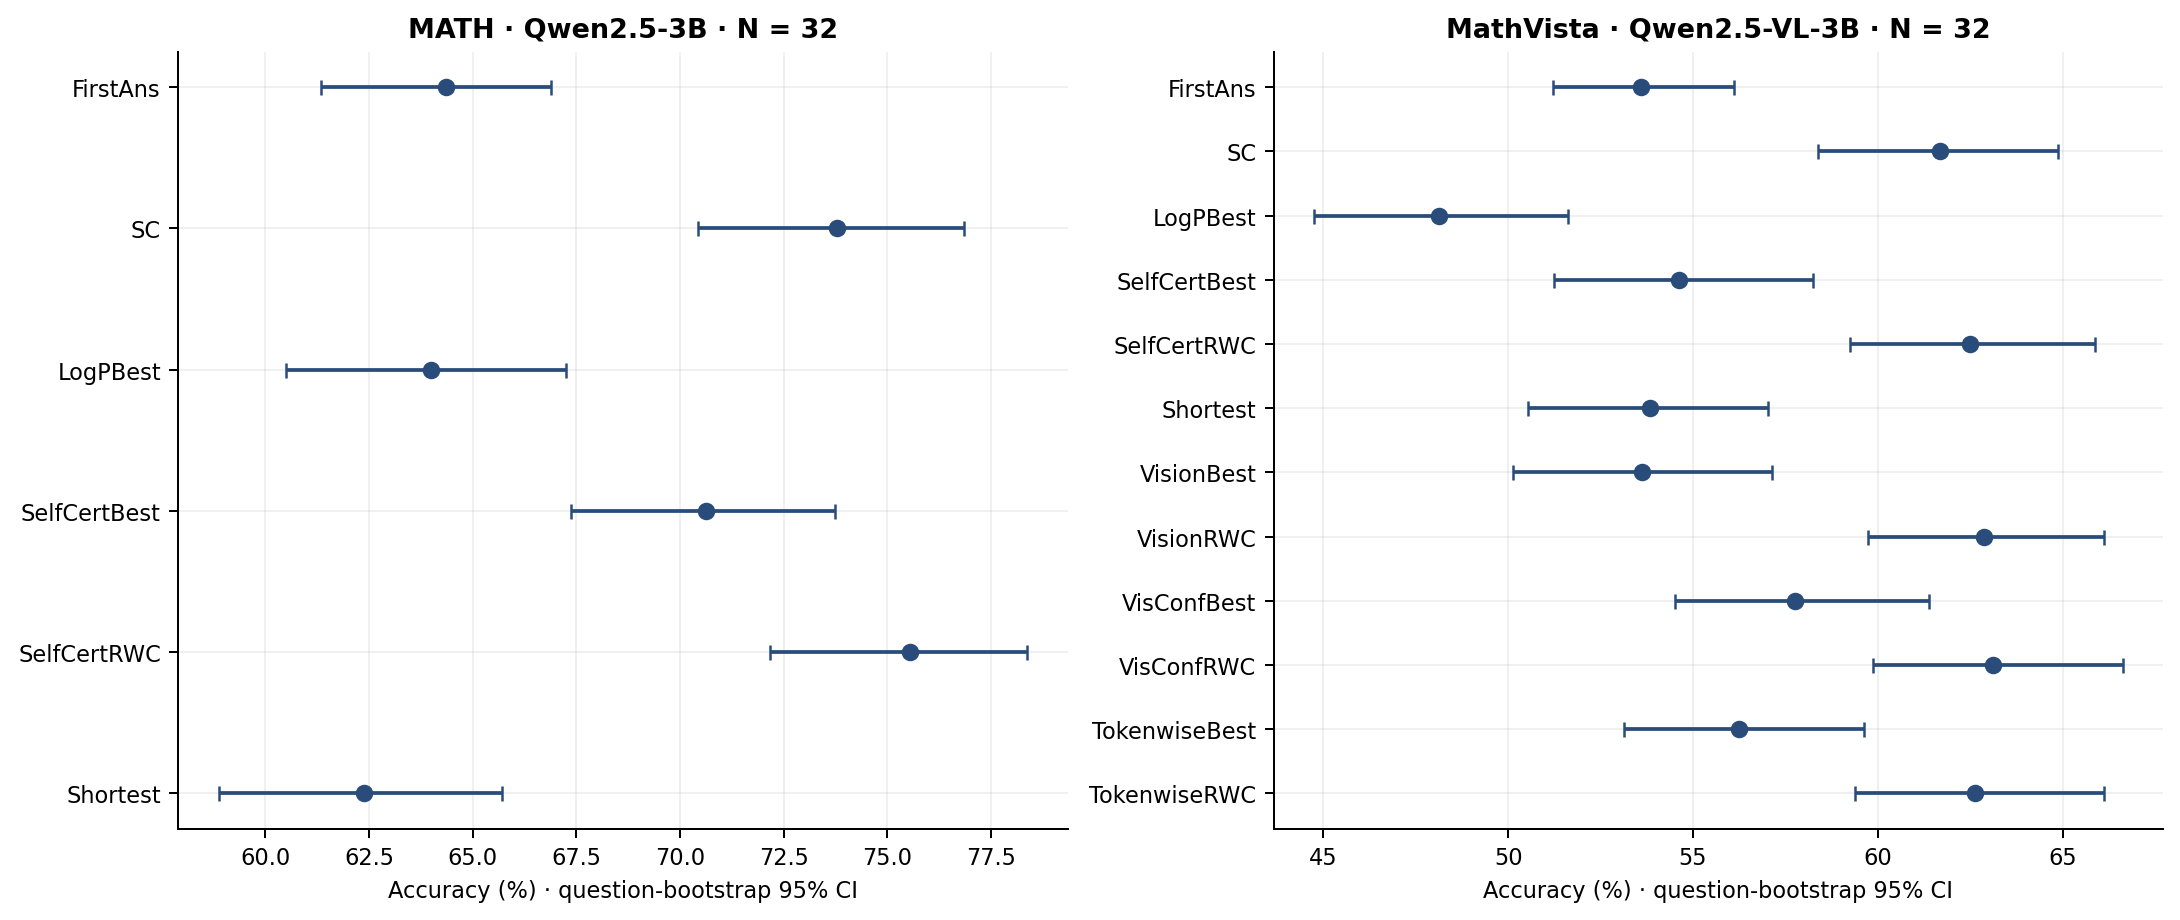

In [5]:
display(Image(filename=str(TASK3 / 'figures/quality_comparison.png')))

## What the signals capture

Quartiles contain eight candidates within each question; top-minus-bottom correctness differences are then averaged across held-out questions. Associations are within question. Undefined Spearman correlations are excluded from the mean and counted in the CSV. Score–length association helps identify possible length effects. These are associations, not calibrated correctness estimates.

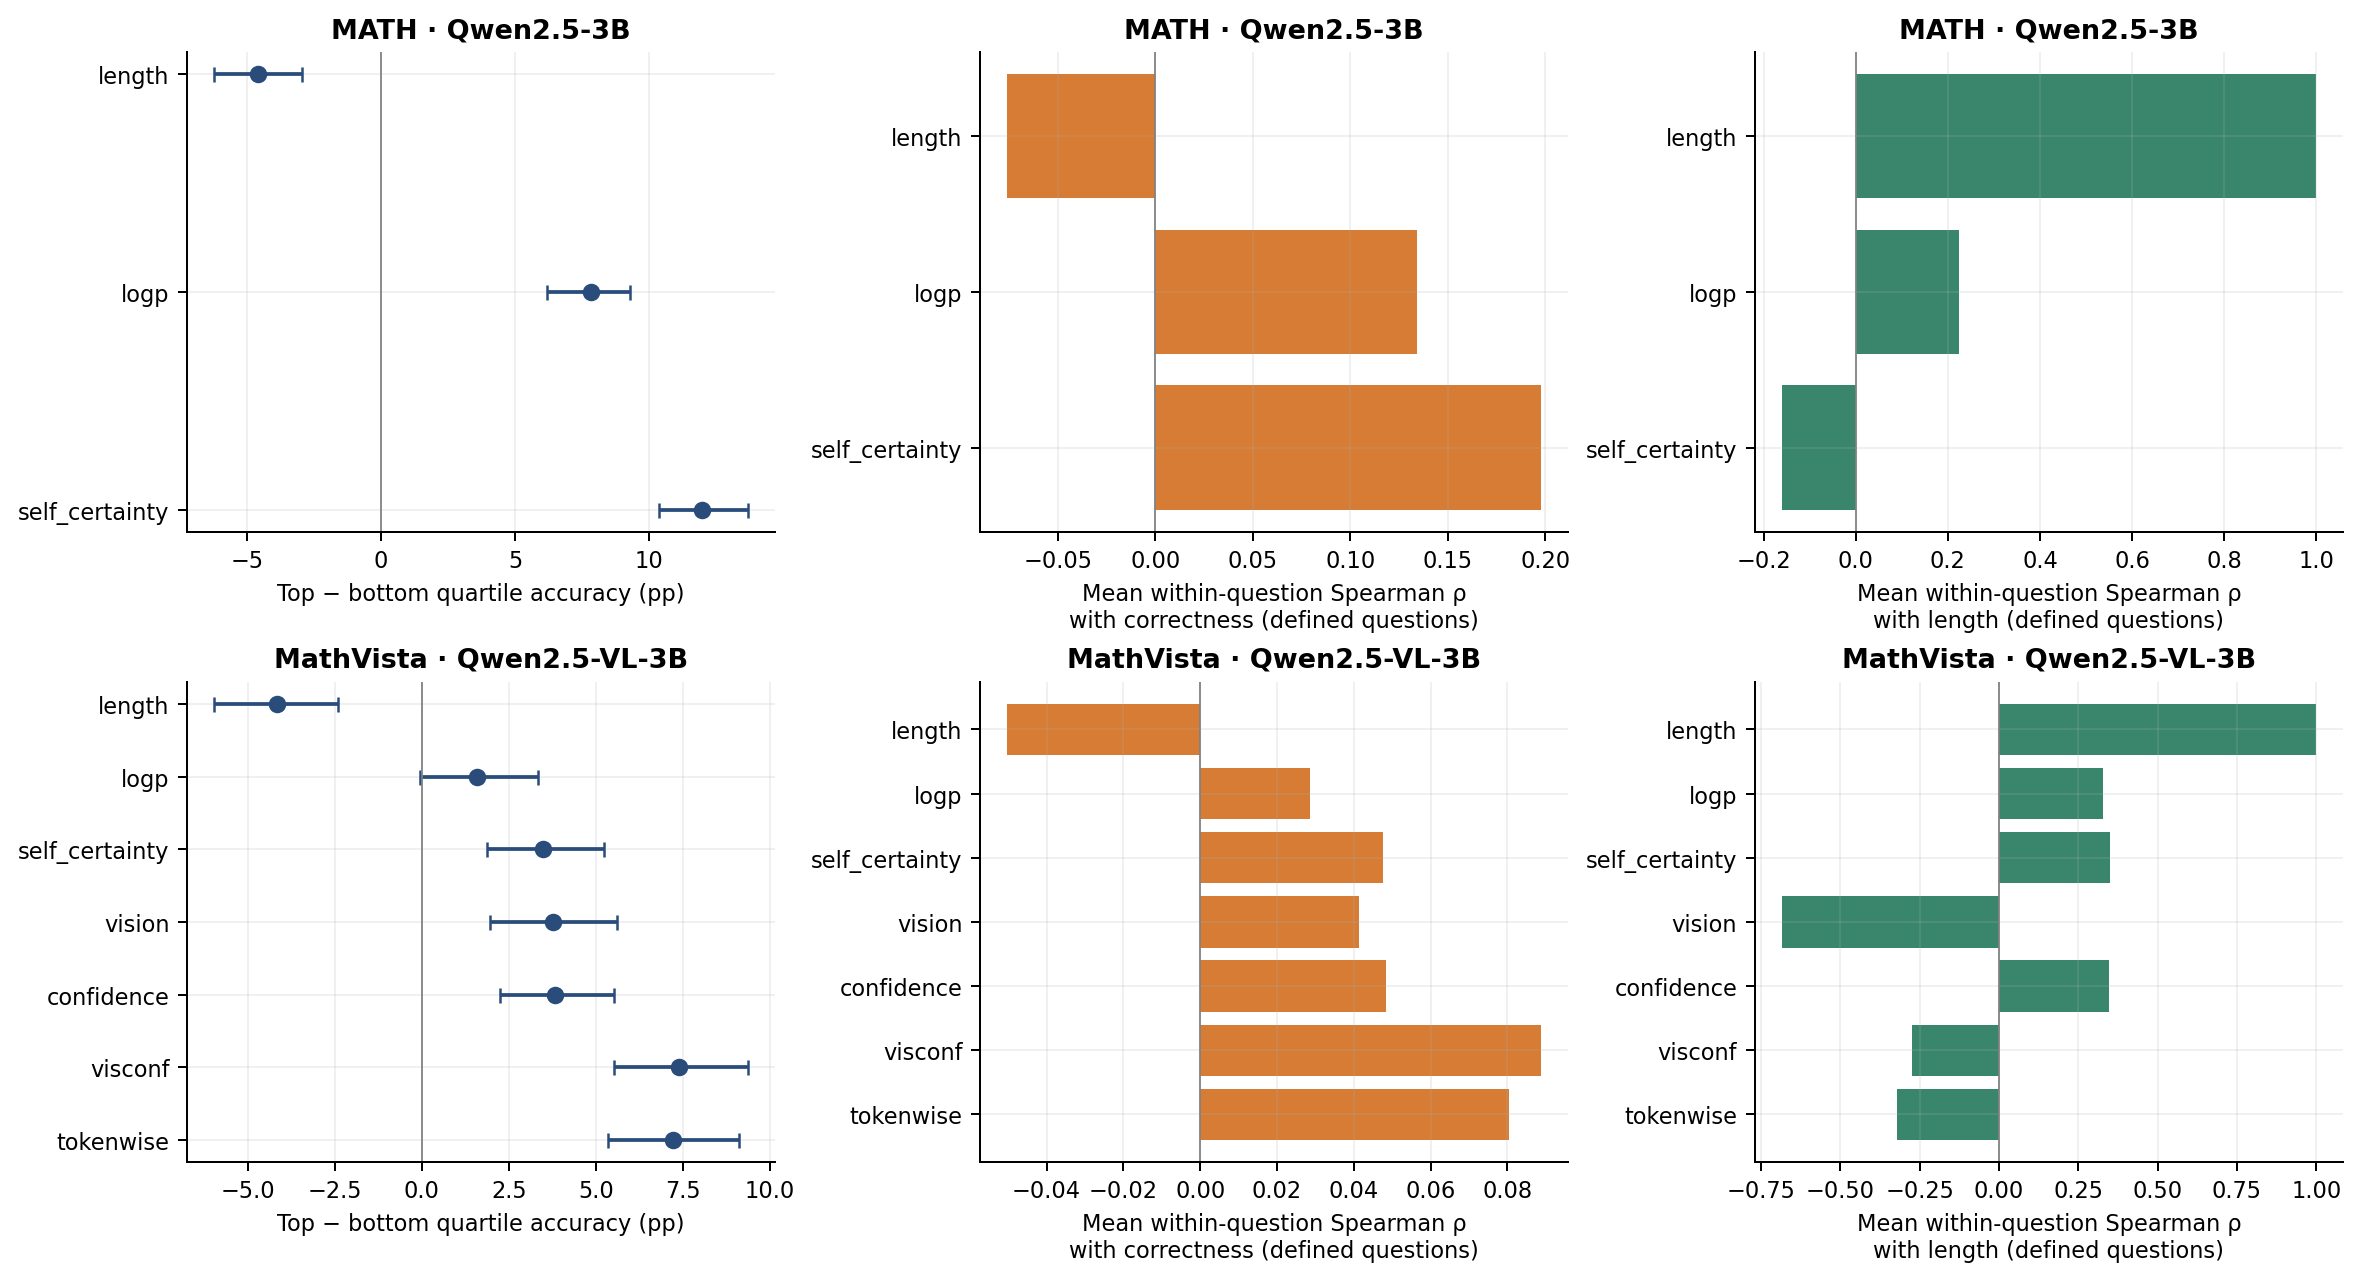

dataset,signal,quartile_accuracy_gap,gap_ci95,spearman_correctness_mean,spearman_correctness_defined_questions,spearman_correctness_undefined_questions,spearman_length_mean,spearman_length_defined_questions,spearman_length_undefined_questions
math,length,-0.0459375,"[-0.06250390625, -0.029375]",-0.07632595054396821,469,331,1.0,800,0
math,logp,0.07828125,"[0.061875, 0.09312890624999999]",0.13401181953820637,469,331,0.22450990220048075,800,0
math,self_certainty,0.11984375,"[0.10375, 0.1371875]",0.19804108649285113,469,331,-0.16109595817293734,800,0
mathvista,length,-0.04140625,"[-0.059691406249999995, -0.02405468750000001]",-0.05039063043904237,634,166,1.0,795,5
mathvista,logp,0.0159375,"[-0.000625, 0.033285156249999996]",0.02868328825953539,634,166,0.3289814558958108,795,5
mathvista,self_certainty,0.03484375,"[0.01875, 0.0523515625]",0.047665037676168906,634,166,0.3493333584506632,795,5
mathvista,vision,0.0378125,"[0.01952734375, 0.0559375]",0.04124393736872656,634,166,-0.68575204458455

In [6]:
display(Image(filename=str(TASK3 / 'figures/signal_associations.png')))
print((TASK3 / 'analysis/signal_associations.csv').read_text())

## Visual confidence and tokenwise fusion

Visual engagement divides image-attention mass by image + prompt-text + generated-text mass. Per-prefix KL calibration uses pooled token 5th/95th linear percentiles. VisConf multiplies rollout mean calibrated confidence by rollout mean visual engagement; tokenwise fusion averages their token products. Their difference equals within-rollout population covariance. For this retrospective N=32 analysis, confidence uses all 32 candidates; live stopping recalibrates only on revealed prefixes.

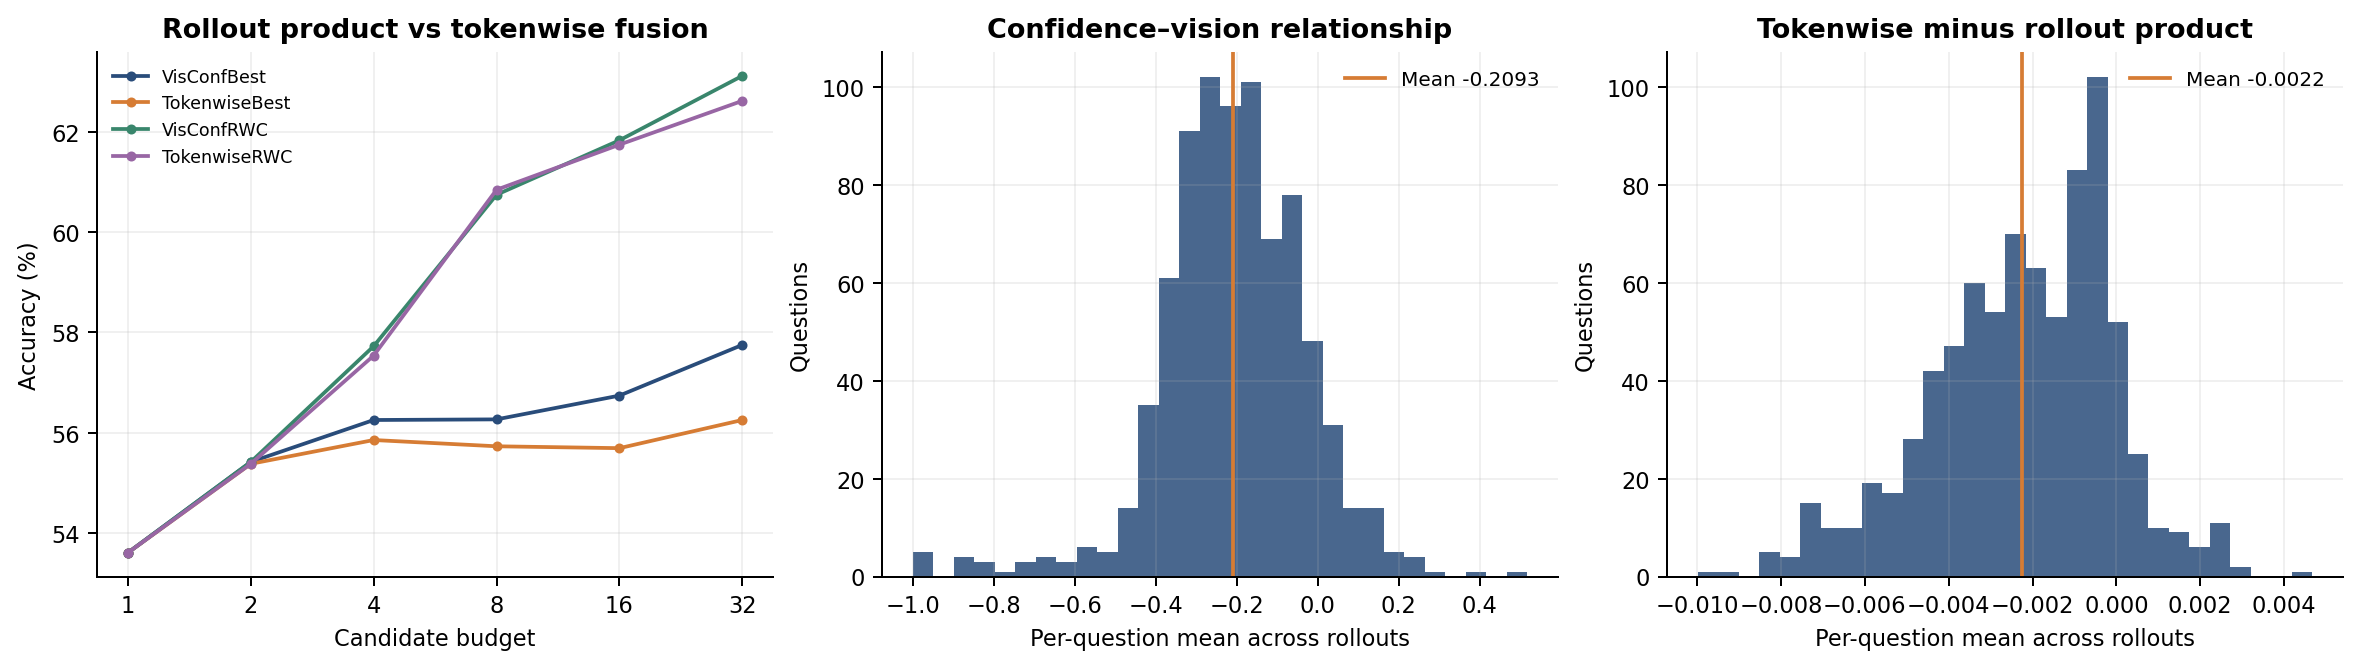

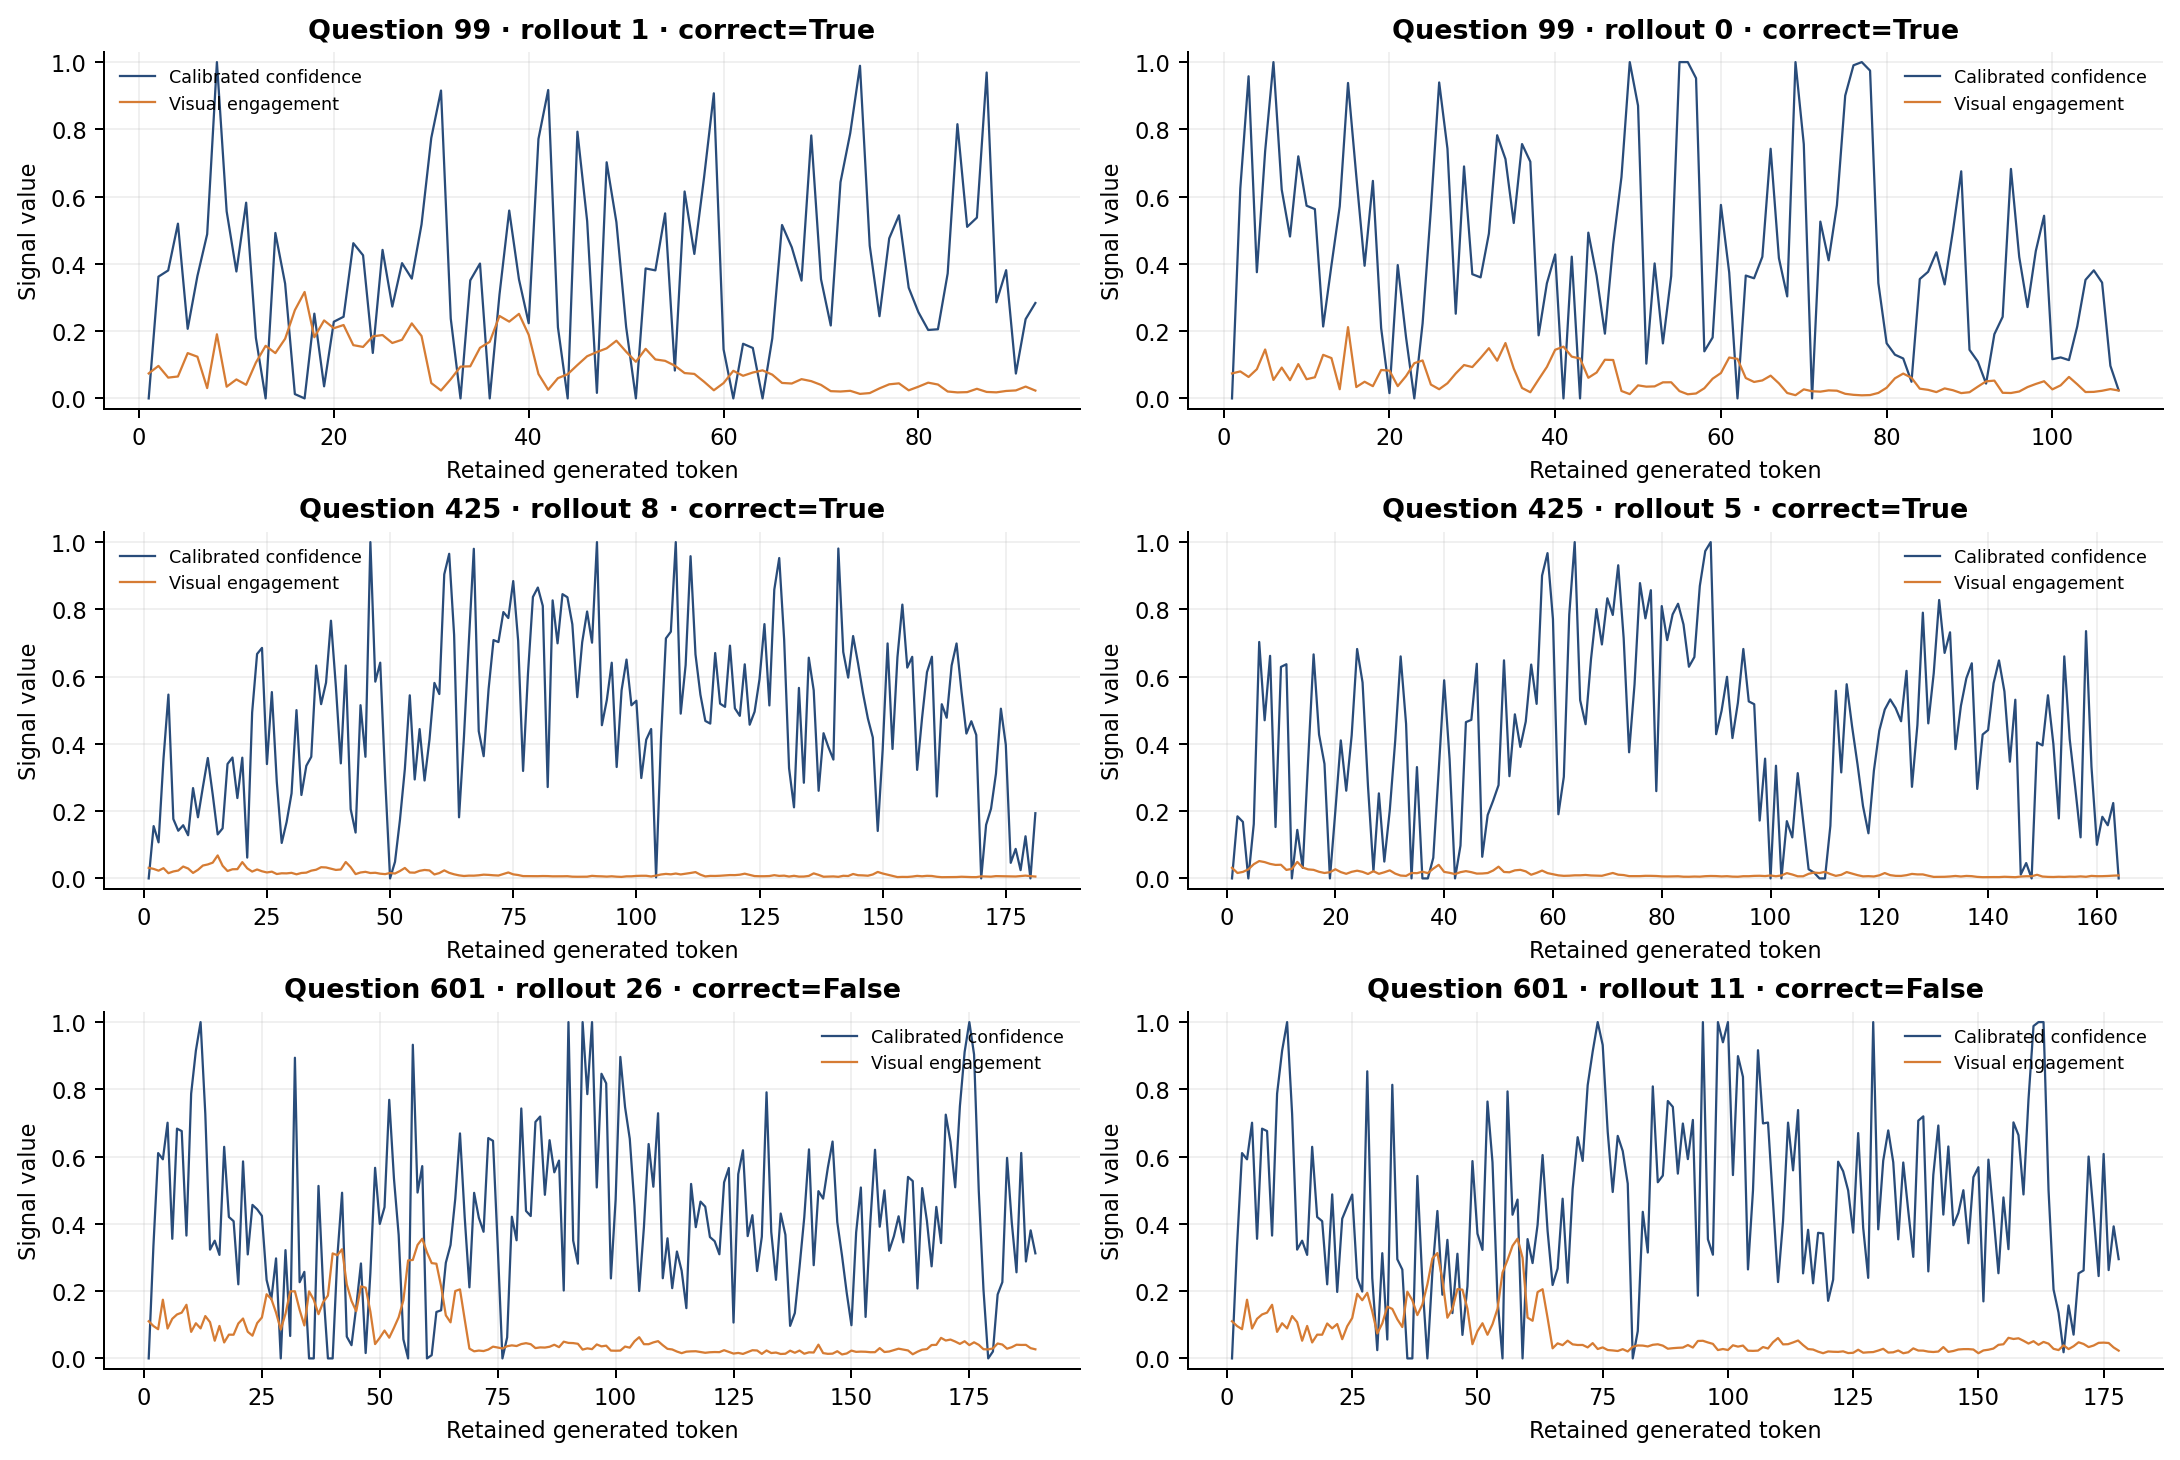

In [7]:
display(Image(filename=str(TASK3 / 'figures/visual_fusion.png')))
display(Image(filename=str(TASK3 / 'figures/fixed_trajectories.png')))

## Adaptive allocation

Both controllers inspect completed prefixes at 4, 8, 16 and otherwise stop at 32, and both return current SC. Agreement needs a unique nonmissing winner with support ≥τ. Quality also needs SC/RWC agreement and normalized RWC margin ≥γ; MATH uses self-certainty, MathVista uses VisConf. Lowest development token cost within 1 pp of development SC32 selects the threshold; held-out labels do not tune it. Error bars represent question-bootstrap accuracy intervals. The 1 pp development rule does not guarantee the same held-out loss.

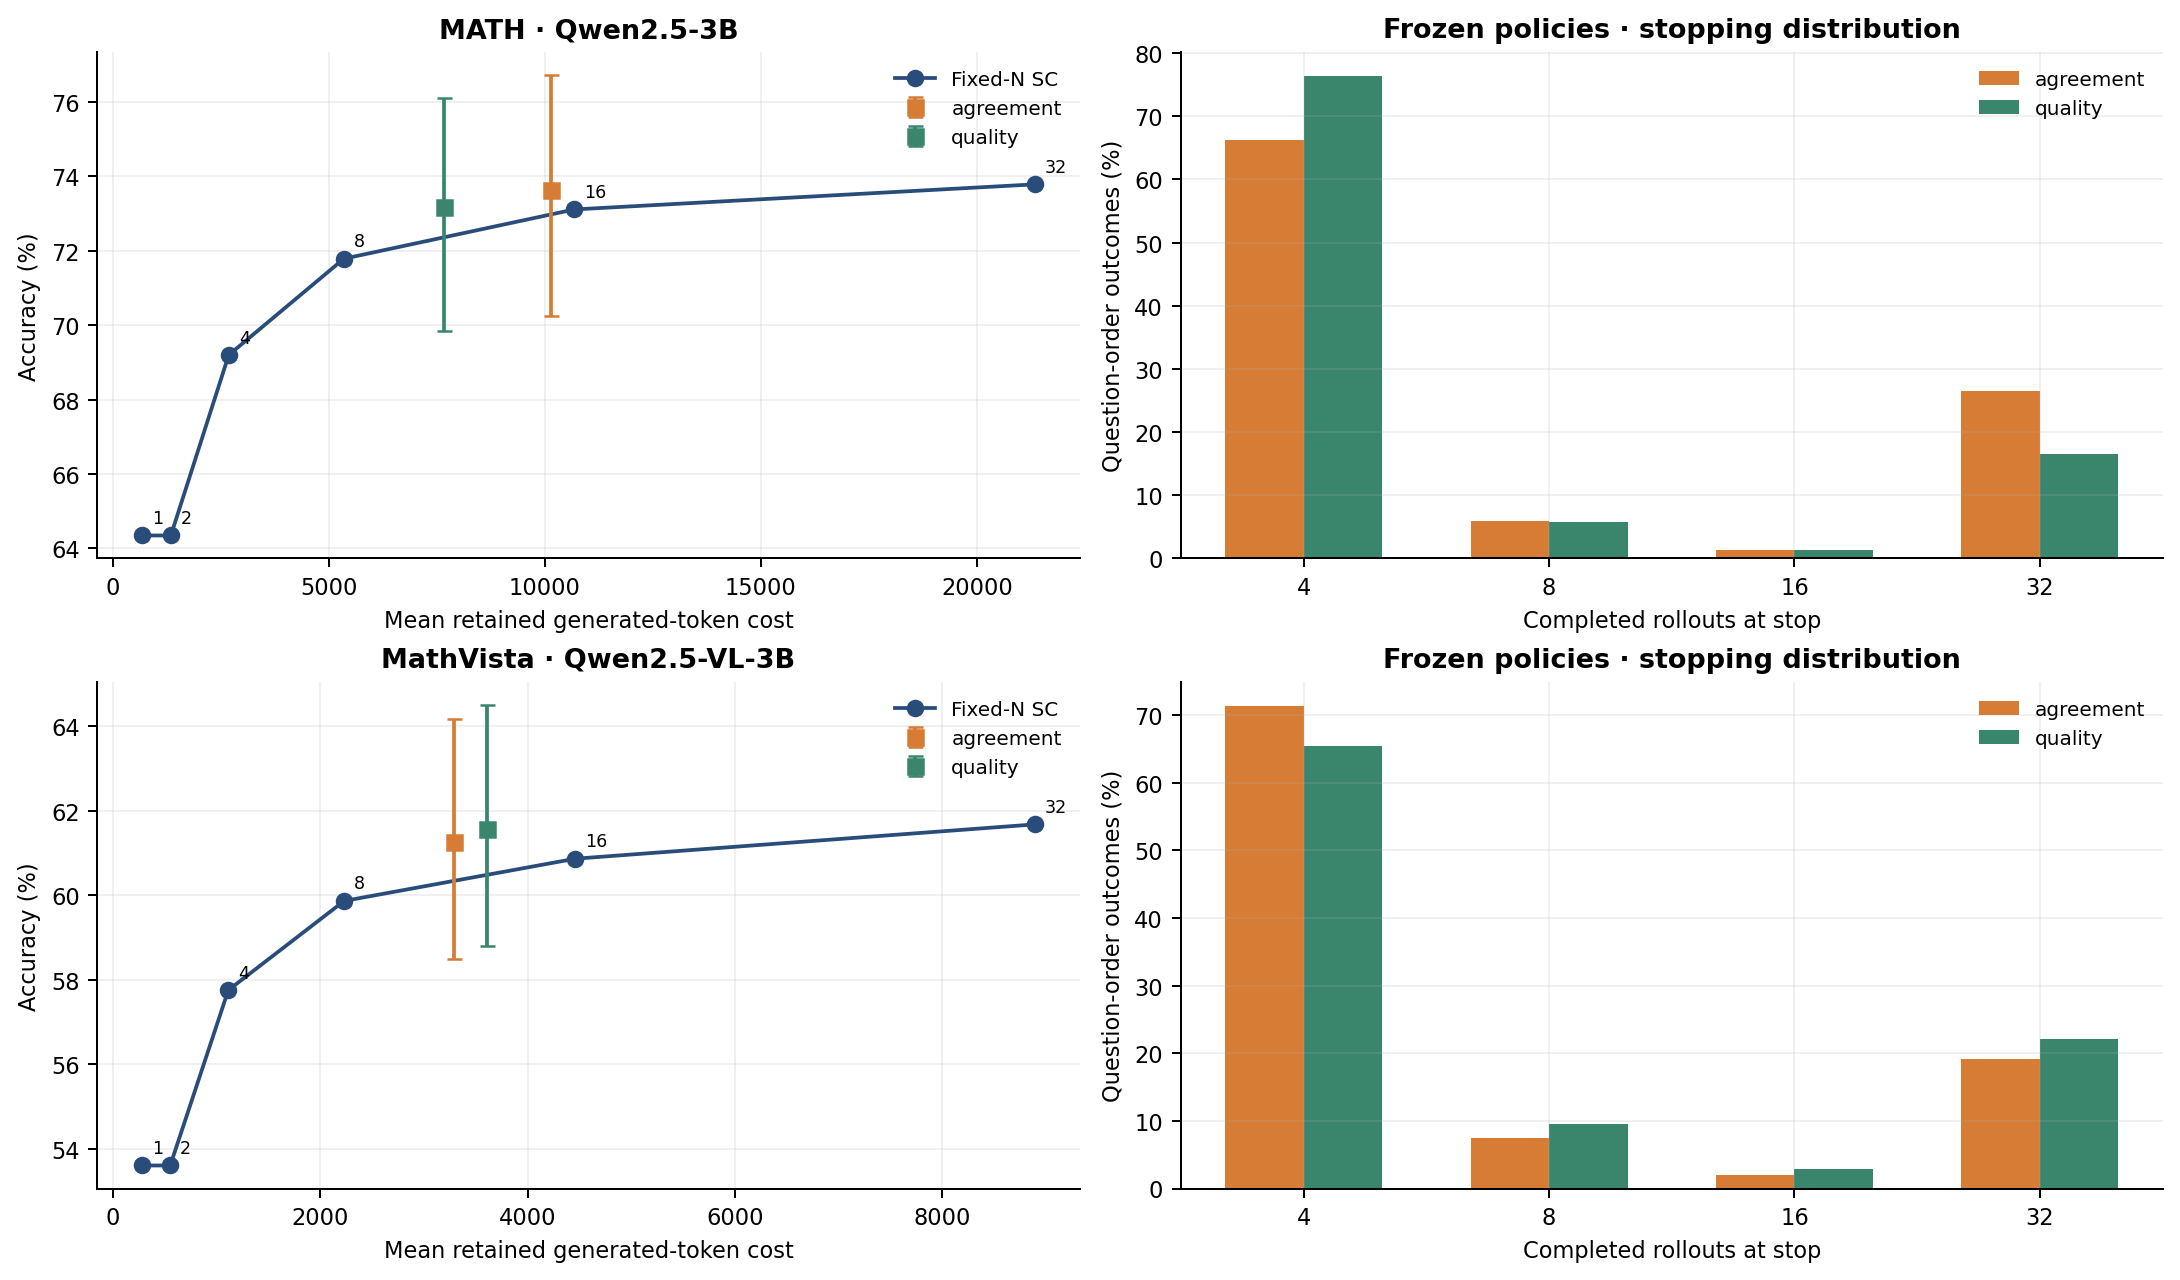

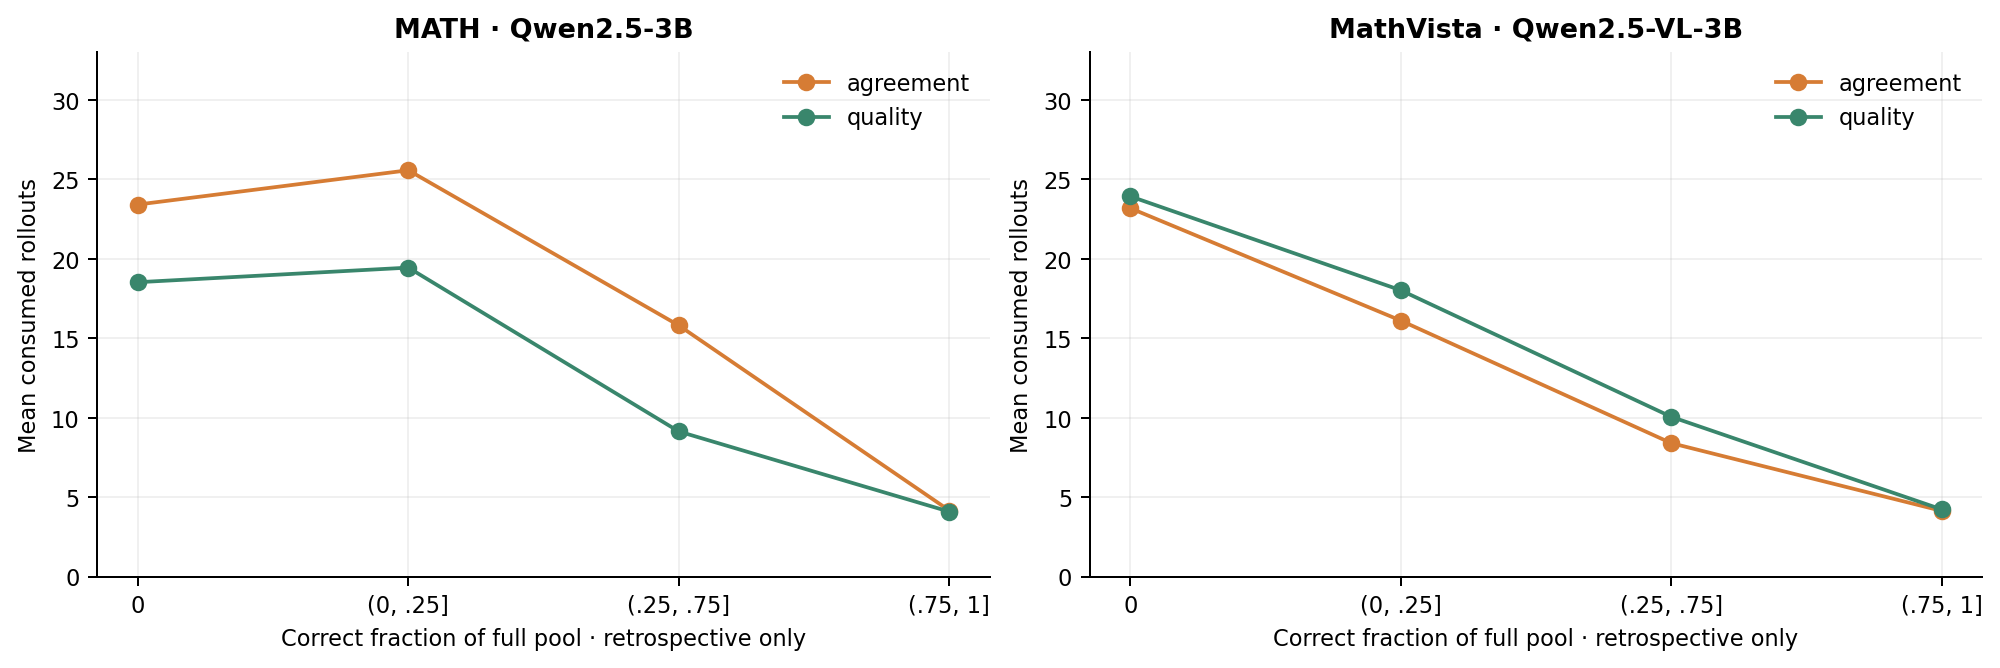

dataset,family,tau,gamma,accuracy,ci95,token_cost,mean_rollouts,incorrect_early_stop_rate,fixed32_recoverable_early_stop_rate
math,agreement,0.625,0.0,0.736375,"[0.7023718750000001, 0.767253125]",10139.981000000002,11.824000000000002,0.0825,0.006375
math,quality,0.5,0.0,0.7317499999999998,"[0.698371875, 0.7611249999999999]",7663.055375,9.0075,0.144,0.016375
mathvista,agreement,0.5,0.0,0.612625,"[0.584990625, 0.6416281250000001]",3290.3146250000004,9.891,0.216875,0.039
mathvista,quality,0.5,0.0,0.615625,"[0.5878687499999999, 0.645003125]",3613.0415,10.93,0.193375,0.0315

dataset,family,adaptive_accuracy,adaptive_cost,nearest_fixed_N,fixed_accuracy,fixed_cost,cost_difference,note
math,agreement,0.736375,10139.981000000002,16,0.7311250000000001,10677.742750000001,-537.7617499999997,Nearest observed mean cost; not exactly matched compute.
math,quality,0.7317499999999998,7663.055375,8,0.7178749999999999,5344.108500000001,2318.9468749999987,Nearest observed mean cost; not exactly matched com

In [8]:
display(Image(filename=str(TASK3 / 'figures/adaptive_inference.png')))
display(Image(filename=str(TASK3 / 'figures/adaptive_retrospective.png')))
print((TASK3 / 'analysis/adaptive.csv').read_text())
print((TASK3 / 'analysis/matched_cost.csv').read_text())

## Live breadth versus refinement

All three strategies have 3,072 output tokens of allowance. Single long: one call capped at 3,072. Parallel: three independently seeded calls capped at 1,024, followed by SC. Sequential: reuse parallel_0 verbatim, then one 2,048-token critique/revision call; always return the revision. Native template, original problem, prescribed system/instructions, FP16, no quantization, batch 1, temperature 0.7, top-p 0.8, top-k 20 and repetition penalty 1.0 are fixed.

Actual tokens differ because of early termination. Complete outputs include EOS; retained counts are separate. Sequential includes the entire critique and longer revision prompt, with initial cost charged to both strategies. Parallel samples ran serially, so times sum. Same A100, synchronized inference timing, excluding loading/smoke/disk writes. Only 50 questions: avoid strong ranking claims.

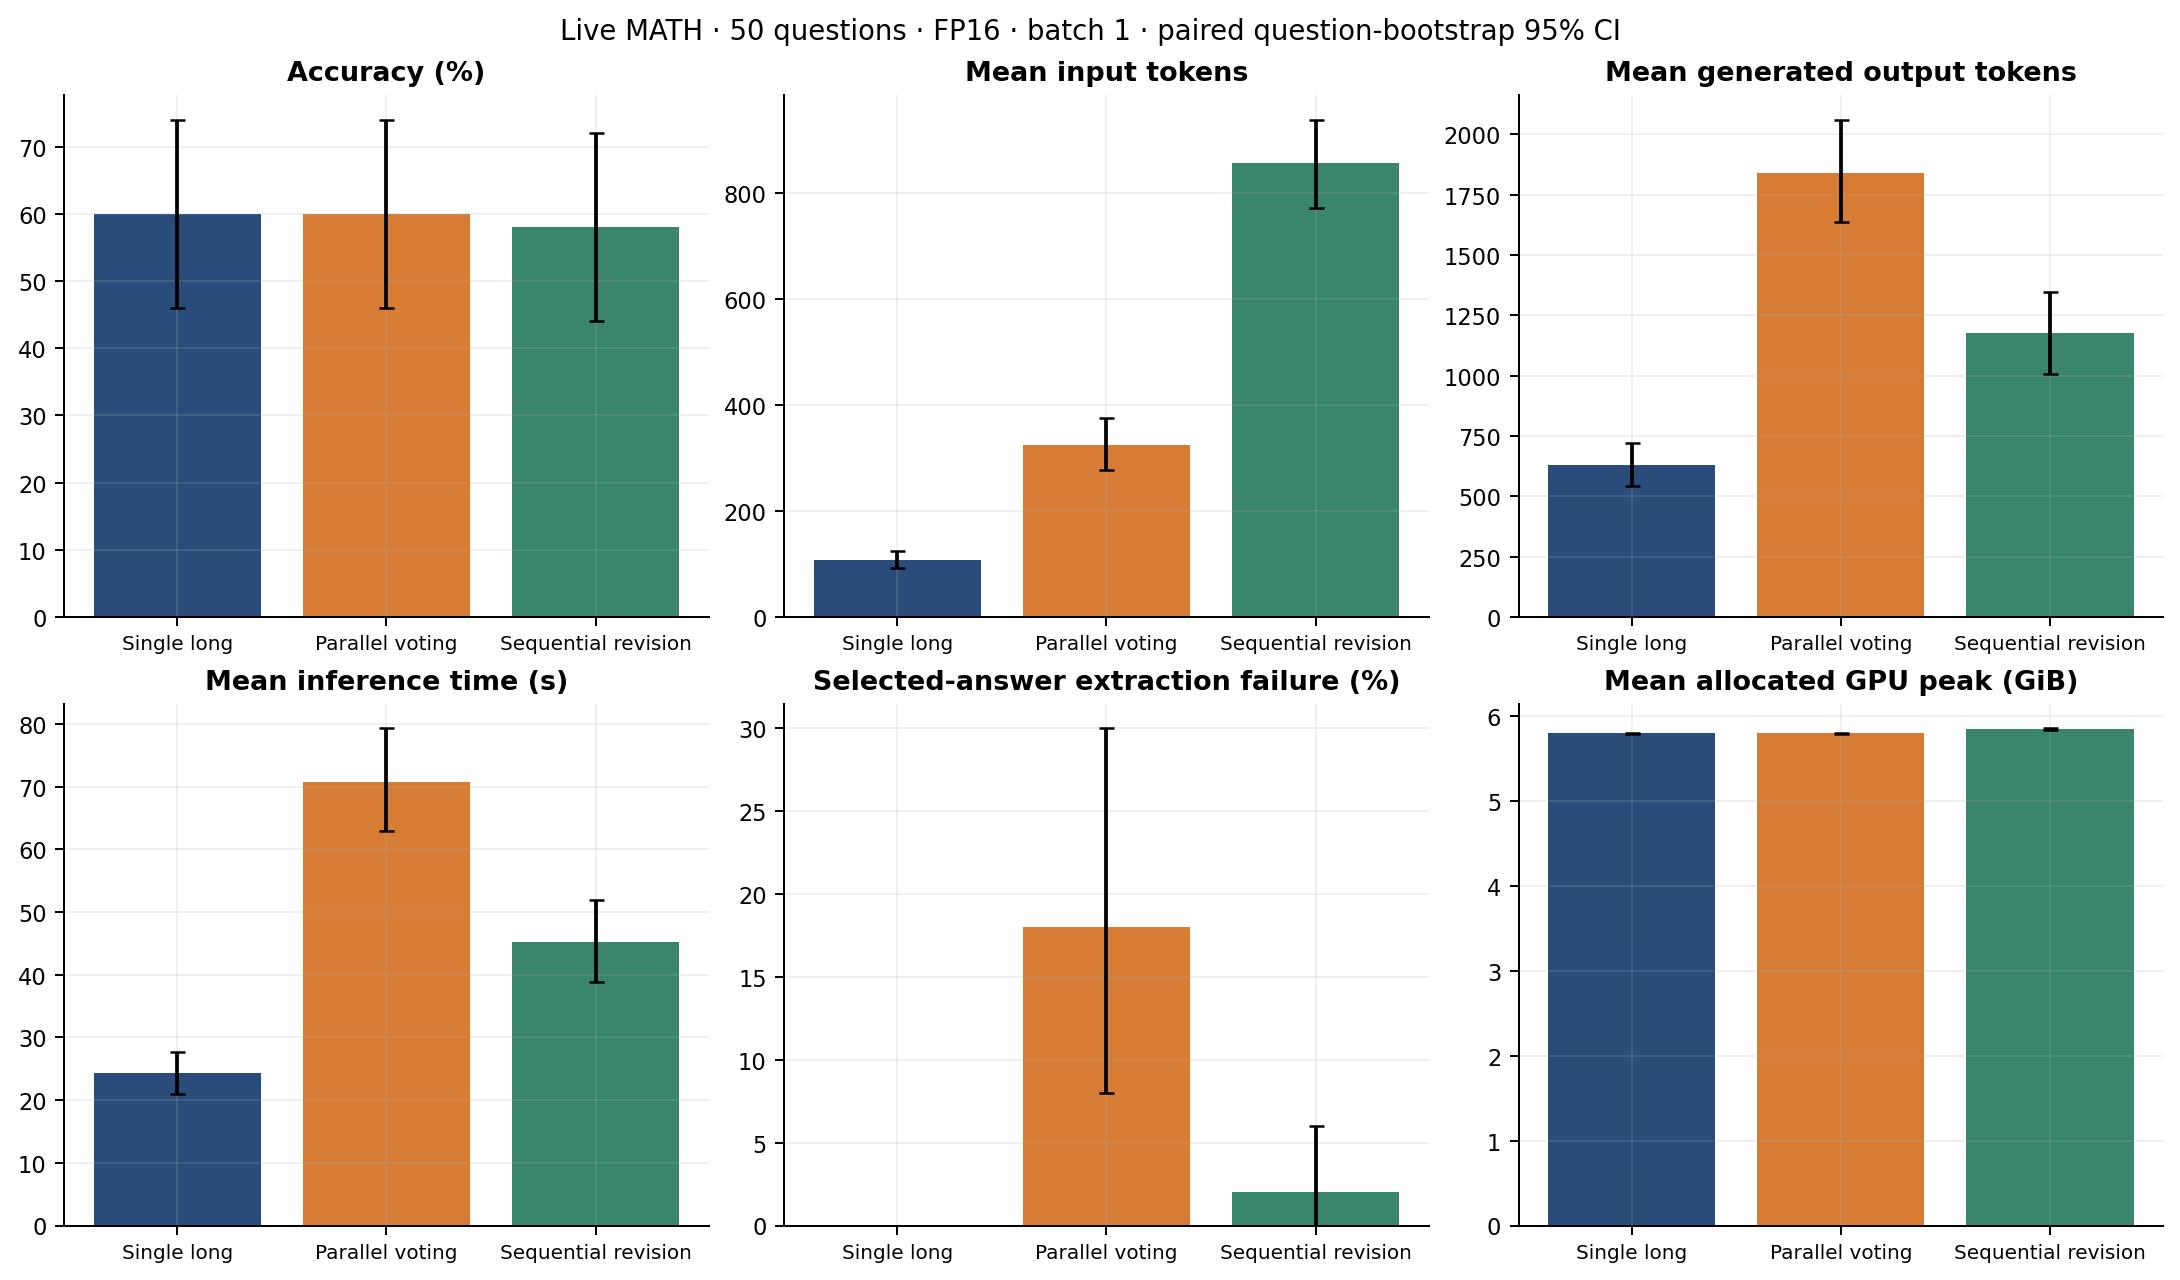

Revision transitions: {'False_to_False': 21, 'False_to_True': 1, 'True_to_False': 0, 'True_to_True': 28}
Paired accuracy differences:
parallel_minus_single_long {'mean': 0.0, 'ci95': [-0.12, 0.12]}
sequential_minus_single_long {'mean': -0.02, 'ci95': [-0.14, 0.1]}
sequential_minus_parallel {'mean': -0.02, 'ci95': [-0.1, 0.04]}


In [9]:
display(Image(filename=str(TASK3 / 'figures/live_strategies.png')))
live = json.loads((TASK3 / 'results/live_scoring/summary.json').read_text())
print('Revision transitions:', live['revision_transitions'])
print('Paired accuracy differences:')
for name, row in live['paired_differences'].items():
    print(name, row['correct'])

## Resource and per-call diagnostics

Truncation and extraction failures remain in scoring. The per-call table separates the three short samples, long response and revision; strategy-selected failure rates appear above. Physical runtime counts each generated call once, whereas strategy comparisons charge the shared initial response to both strategies.

In [10]:
print((TASK3 / 'analysis/live_call_rates.csv').read_text())
resources = json.loads((TASK3 / 'analysis/resources.json').read_text())
print(json.dumps(resources, indent=2))

call,questions,extraction_failed,truncated,reached_cap,mean_input_tokens,mean_output_tokens,mean_seconds
single_long,50,0,0,0,108.38,631.8,24.315954746479974
parallel_0,50,9,10,10,108.38,602.52,23.18460548916002
parallel_1,50,6,6,6,108.38,610.84,23.506930038759947
parallel_2,50,8,8,8,108.38,626.74,24.14062731951995
revision,50,1,1,1,748.1,574.16,22.109817719480006

{
  "gpu_environment": {
    "gpu": "NVIDIA A100-SXM4-40GB",
    "compute_capability": [
      8,
      0
    ],
    "vram_bytes": 42405855232,
    "cuda": "13.0",
    "python": "3.13.16",
    "packages": {
      "torch": "2.11.0+cu130",
      "transformers": "5.21.0",
      "datasets": "4.8.5",
      "accelerate": "1.15.0",
      "huggingface_hub": "1.33.0",
      "tokenizers": "0.23.3",
      "numpy": "2.1.3",
      "safetensors": "0.8.0",
      "math-verify": "0.9.0",
      "sympy": "1.14.0",
      "latex2sympy2_extended": "1.11.0",
      "antlr4-python3-runtime": "4.13.2",
      "pandas": "2.2.3",
      "pyarrow": "23.0.

## Results and interpretation

In [11]:
display(Markdown((TASK3 / 'analysis/RESULTS.md').read_text()))

# Task 3 results

Held-out evaluation: 800 questions per dataset, ten nested candidate orders per question. Intervals bootstrap questions after averaging orders (1,000 paired resamples, seed 6304). The two model–dataset combinations do not isolate a causal effect of vision.

## Fixed budget: N = 32

| Dataset | Method | Accuracy (%) | 95% CI | Δ vs SC (pp) | Δ 95% CI (pp) | Token cost |
| --- | --- | --- | --- | --- | --- | --- |
| MATH · Qwen2.5-3B | FirstAns | 64.350 | [61.34, 66.89] | -9.438 | [-11.101, -7.849] | 669.8 |
| MATH · Qwen2.5-3B | SC | 73.787 | [70.42, 76.86] | +0.000 | [0.0, 0.0] | 21347.0 |
| MATH · Qwen2.5-3B | LogPBest | 64.000 | [60.50, 67.25] | -9.788 | [-12.412, -7.2] | 21347.0 |
| MATH · Qwen2.5-3B | SelfCertBest | 70.625 | [67.37, 73.75] | -3.162 | [-5.563, -0.837] | 21347.0 |
| MATH · Qwen2.5-3B | SelfCertRWC | 75.550 | [72.17, 78.38] | +1.762 | [0.675, 2.801] | 21347.0 |
| MATH · Qwen2.5-3B | Shortest | 62.375 | [58.88, 65.71] | -11.413 | [-14.088, -8.962] | 21347.0 |
| MathVista · Qwen2.5-VL-3B | FirstAns | 53.600 | [51.22, 56.11] | -8.075 | [-10.025, -6.162] | 277.8 |
| MathVista · Qwen2.5-VL-3B | SC | 61.675 | [58.37, 64.89] | +0.000 | [0.0, 0.0] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | LogPBest | 48.125 | [44.75, 51.62] | -13.550 | [-17.0, -10.262] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | SelfCertBest | 54.625 | [51.25, 58.25] | -7.050 | [-10.151, -3.8] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | SelfCertRWC | 62.500 | [59.25, 65.88] | +0.825 | [-0.55, 2.138] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | Shortest | 53.850 | [50.54, 57.03] | -7.825 | [-11.027, -4.923] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | VisionBest | 53.625 | [50.12, 57.12] | -8.050 | [-11.337, -4.95] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | VisionRWC | 62.875 | [59.75, 66.12] | +1.200 | [-0.312, 2.838] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | VisConfBest | 57.750 | [54.50, 61.38] | -3.925 | [-6.976, -0.896] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | VisConfRWC | 63.125 | [59.88, 66.62] | +1.450 | [0.037, 2.975] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | TokenwiseBest | 56.250 | [53.12, 59.63] | -5.425 | [-8.425, -2.362] | 8897.8 |
| MathVista · Qwen2.5-VL-3B | TokenwiseRWC | 62.625 | [59.38, 66.13] | +0.950 | [-0.413, 2.438] | 8897.8 |

Self-certainty RWC reaches 75.55% on MATH versus 73.7875% for SC. MathVista VisConf RWC reaches 63.125% versus 61.675% for SC. These compare selectors on identical revealed candidate sets. Oracle coverage is a retrospective upper bound, not an implementable selector. Shortest-rollout control and score–length associations prevent treating every quality gain as evidence of calibrated correctness.

## Adaptive sampling

| Dataset | Controller | τ | γ | Accuracy (%) | Mean token cost | Mean rollouts | Tokens saved vs SC32 (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| math | agreement | 0.625 | 0.0 | 73.638 | 10140.0 | 11.824 | 52.50 |
| math | quality | 0.5 | 0.0 | 73.175 | 7663.1 | 9.008 | 64.10 |
| mathvista | agreement | 0.5 | 0.0 | 61.262 | 3290.3 | 9.891 | 63.02 |
| mathvista | quality | 0.5 | 0.0 | 61.562 | 3613.0 | 10.930 | 59.39 |

Thresholds were selected on 200 development questions per dataset and frozen before held-out summaries. Both controllers return current SC. The 1 pp tolerance constrains development accuracy, not a guaranteed held-out loss. Compare the full fixed-SC cost curve in the figure; nearest-cost rows in matched_cost.csv are approximate observed comparisons, not exactly equal-cost trials. Incorrect and recoverable early-stop rates use all question-order outcomes as denominator. Full-pool correctness buckets are retrospective diagnostics only.

## Signal and fusion findings

MathVista calibrated confidence and visual engagement have mean within-rollout correlation −0.20934 (rollouts averaged within each question). Tokenwise fusion minus the rollout product averages −0.00224338, exactly matching the saved population covariance. This negative relationship makes the two fusion definitions different. The fixed six MathVista trajectories were selected before metrics; their confidence uses the complete N=32 set, appropriate only for this retrospective display. Attention associations do not prove causal grounding.

## Live comparison

| Strategy | Correct / 50 | Accuracy (%) | Input tokens | Output tokens | Time (s) | Selected truncation (%) | Extraction failure (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Single long | 30 | 60.0 | 108.38 | 631.80 | 24.32 | 0.0 | 0.0 |
| Parallel voting | 30 | 60.0 | 325.14 | 1840.10 | 70.83 | 18.0 | 18.0 |
| Sequential revision | 29 | 58.0 | 856.48 | 1176.68 | 45.29 | 2.0 | 2.0 |

All three have the same 3,072-token output allowance; actual use differs. Output cost includes EOS; retained-token counts are separate in the CSV. Parallel samples were executed serially, so runtime is summed; the shared initial call is charged to both parallel and sequential. Sequential includes all critique tokens and the longer input prompt. Loading, smoke and disk writes are outside inference timing. The shared initial answer was correct on 28/50: revision corrected one error, spoiled none, and retained 28 correct answers. Long/parallel each score 30/50; revision scores 29/50. A 50-question comparison supports limited precision rather than a universal strategy ranking.

| Paired accuracy difference | Mean (pp) | 95% CI (pp) |
| --- | --- | --- |
| parallel_minus_single_long | +0.00 | [-12.0, 12.0] |
| sequential_minus_single_long | -2.00 | [-14.0, 10.0] |
| sequential_minus_parallel | -2.00 | [-10.0, 4.0] |

## Audit scope and limitations

All stored chunk and live-call hashes, split/order IDs, selection membership, retained-token costs, development grid selection, fixed/adaptive metrics, and saved confidence intervals are rechecked. Live parsing, grading, revision messages, seeds, limits and costs are independently rechecked on CPU. This report export excludes raw parquet and prepared NPZ arrays; it cannot rerun the original full-distribution token alignment or recompute every VisConf value from raw arrays. Original preparation audits and hashes are retained. Model tensor bytes and GPU timings are recorded evidence, not re-measured by CPU report mode. No gold/future candidates enter selection or stopping.


## Aligned qualitative evidence

Offline examples are the first lexicographic held-out questions satisfying each saved condition, using the earliest qualifying order. Live examples are the first two lexicographic questions per transition. These illustrate selection disagreement, recoverable premature stopping and revision; they are not representative frequency estimates. Full raw response text for the offline pools remains in the supplied parquet. All live initial/revision text is retained here.

In [12]:
display(Markdown((TASK3 / 'analysis/QUALITATIVE.md').read_text()))

# Aligned qualitative examples

Offline selection: first lexicographic held-out question satisfying each saved failure/disagreement condition; earliest qualifying order. Examples are descriptive and selected after outcomes, not prevalence estimates. The underlying generation text remains in the supplied parquet; these panels align the problem, reference, extracted candidates and decisions. Live revision examples use the first two lexicographic IDs per transition.

## math · premature_stop_recoverable · test:1423

When a fair six-sided die is tossed on a table top, the bottom face cannot be seen.  What is the probability that the product of the  numbers on the five faces that can be seen is divisible by 6?

Reference: `1`. Order 4; revealed 4 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 8 | \frac{5}{6} | False | 756 | -0.1912 | 24.5822 |
| 3 | 1 | True | 861 | -0.095 | 24.8053 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "premature_stop_recoverable",
    "family": "agreement",
    "sample_id": "test:1423",
    "accuracy": 0.0,
    "token_cost": 2990,
    "rollouts": 4,
    "oracle_coverage": 0.0,
    "pool_oracle_coverage": 0.0,
    "distinct_groups": 2,
    "sampling_failure": 1.0,
    "selection_failure": 0.0,
    "selected_rollout_id": 8,
    "stop_n": 4,
    "order_index": 4,
    "incorrect_early_stop": true,
    "fixed32_would_recover": true
  },
  "SC_votes": {
    "MATH_GROUP_01": 3,
    "MATH_GROUP_00": 1
  },
  "RWC_votes": {
    "MATH_GROUP_01": 12,
    "MATH_GROUP_00": 0
  }
}
```

## math · premature_stop_recoverable · test:1153

How many non-congruent right triangles are there, all of whose sides have positive integer lengths, and one of whose legs (i.e. not the hypotenuse) has length $162$?

Reference: `4`. Order 8; revealed 4 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 25 | 2 | False | 1067 | -0.0683 | 26.3498 |
| 0 | 4 | True | 1052 | -0.08 | 26.0453 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "premature_stop_recoverable",
    "family": "quality",
    "sample_id": "test:1153",
    "accuracy": 0.0,
    "token_cost": 4322,
    "rollouts": 4,
    "oracle_coverage": 0.0,
    "pool_oracle_coverage": 0.0,
    "distinct_groups": 3,
    "sampling_failure": 1.0,
    "selection_failure": 0.0,
    "selected_rollout_id": 25,
    "stop_n": 4,
    "order_index": 8,
    "incorrect_early_stop": true,
    "fixed32_would_recover": true
  },
  "SC_votes": {
    "MATH_GROUP_01": 2,
    "MATH_GROUP_00": 1,
    "MATH_GROUP_02": 1
  },
  "RWC_votes": {
    "MATH_GROUP_01": 6,
    "MATH_GROUP_00": 0,
    "MATH_GROUP_02": 6
  }
}
```

## math · SC_wrong_SelfCertBest_correct · test:1230

A standard die is rolled. What is the probability that the number shown is not an even prime?

Reference: `\frac{5}{6}`. Order 0; revealed 32 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 20 | \frac{1}{2} | False | 396 | -0.0931 | 27.5525 |
| 7 | \frac{5}{6} | True | 410 | -0.1018 | 27.6147 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "SC_wrong_SelfCertBest_correct",
    "sample_id": "test:1230",
    "order_index": 0,
    "SC_rollout": 20,
    "SelfCertBest_rollout": 7
  },
  "SC_votes": {
    "MATH_GROUP_00": 17,
    "MATH_GROUP_02": 13,
    "MATH_GROUP_01": 2
  },
  "RWC_votes": {
    "MATH_GROUP_00": 526,
    "MATH_GROUP_02": 450,
    "MATH_GROUP_01": 16
  }
}
```

## math · SC_correct_SelfCertBest_wrong · test:1153

How many non-congruent right triangles are there, all of whose sides have positive integer lengths, and one of whose legs (i.e. not the hypotenuse) has length $162$?

Reference: `4`. Order 0; revealed 32 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 3 | 4 | True | 1424 | -0.0524 | 25.0318 |
| 9 | 9 | False | 684 | -0.1282 | 26.9251 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "SC_correct_SelfCertBest_wrong",
    "sample_id": "test:1153",
    "order_index": 0,
    "SC_rollout": 3,
    "SelfCertBest_rollout": 9
  },
  "SC_votes": {
    "MATH_GROUP_06": 8,
    "MATH_GROUP_00": 3,
    "NO_ANSWER": 7,
    "MATH_GROUP_07": 1,
    "MATH_GROUP_02": 1,
    "MATH_GROUP_01": 2,
    "MATH_GROUP_09": 1,
    "MATH_GROUP_10": 1,
    "MATH_GROUP_08": 1,
    "MATH_GROUP_03": 3,
    "MATH_GROUP_05": 1,
    "MATH_GROUP_04": 1,
    "MATH_GROUP_11": 2
  },
  "RWC_votes": {
    "MATH_GROUP_06": 356,
    "MATH_GROUP_00": 136,
    "NO_ANSWER": 86,
    "MATH_GROUP_07": 6,
    "MATH_GROUP_02": 16,
    "MATH_GROUP_01": 32,
    "MATH_GROUP_09": 24,
    "MATH_GROUP_10": 36,
    "MATH_GROUP_08": 38,
    "MATH_GROUP_03": 120,
    "MATH_GROUP_05": 8,
    "MATH_GROUP_04": 20,
    "MATH_GROUP_11": 114
  }
}
```

## mathvista · premature_stop_recoverable · 120

What is the degree of this function?

Reference: `3`. Order 0; revealed 4 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 27 | 1 | False | 236 | -0.3604 | 16.1552 |
| 31 | 3 | True | 302 | -0.3524 | 17.4722 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "premature_stop_recoverable",
    "family": "agreement",
    "sample_id": "120",
    "accuracy": 0.0,
    "token_cost": 918,
    "rollouts": 4,
    "oracle_coverage": 1.0,
    "pool_oracle_coverage": 1.0,
    "distinct_groups": 2,
    "sampling_failure": 0.0,
    "selection_failure": 1.0,
    "selected_rollout_id": 27,
    "stop_n": 4,
    "order_index": 0,
    "incorrect_early_stop": true,
    "fixed32_would_recover": true
  },
  "SC_votes": {
    "1": 3,
    "3": 1
  },
  "RWC_votes": {
    "1": 8,
    "3": 4
  }
}
```

## mathvista · premature_stop_recoverable · 120

What is the degree of this function?

Reference: `3`. Order 0; revealed 4 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 27 | 1 | False | 236 | -0.3604 | 16.1552 |
| 31 | 3 | True | 302 | -0.3524 | 17.4722 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "premature_stop_recoverable",
    "family": "quality",
    "sample_id": "120",
    "accuracy": 0.0,
    "token_cost": 918,
    "rollouts": 4,
    "oracle_coverage": 1.0,
    "pool_oracle_coverage": 1.0,
    "distinct_groups": 2,
    "sampling_failure": 0.0,
    "selection_failure": 1.0,
    "selected_rollout_id": 27,
    "stop_n": 4,
    "order_index": 0,
    "incorrect_early_stop": true,
    "fixed32_would_recover": true
  },
  "SC_votes": {
    "1": 3,
    "3": 1
  },
  "RWC_votes": {
    "1": 8,
    "3": 4
  }
}
```

## mathvista · SC_wrong_SelfCertBest_correct · 11

Subtract all red things. Subtract all tiny matte balls. How many objects are left?

Reference: `5`. Order 0; revealed 32 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 27 | 4 | False | 165 | -0.2687 | 14.115 |
| 23 | 5 | True | 281 | -0.1495 | 15.9496 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "SC_wrong_SelfCertBest_correct",
    "sample_id": "11",
    "order_index": 0,
    "SC_rollout": 27,
    "SelfCertBest_rollout": 23
  },
  "SC_votes": {
    "4": 12,
    "5": 11,
    "6": 4,
    "3": 3,
    "NO_ANSWER": 1,
    "7": 1
  },
  "RWC_votes": {
    "4": 418,
    "5": 314,
    "6": 76,
    "3": 90,
    "NO_ANSWER": 40,
    "7": 54
  }
}
```

## mathvista · SC_correct_SelfCertBest_wrong · 113

How many baseballs are there?

Reference: `20`. Order 0; revealed 32 candidates.

| Rollout | Extracted answer | Correct | Retained tokens | Mean logp | Self-certainty |
| --- | --- | --- | --- | --- | --- |
| 24 | 20 | True | 118 | -0.1118 | 18.3161 |
| 20 | 22 | False | 192 | -0.0755 | 20.2618 |

Decision and prefix votes:

```json
{
  "case": {
    "kind": "SC_correct_SelfCertBest_wrong",
    "sample_id": "113",
    "order_index": 0,
    "SC_rollout": 24,
    "SelfCertBest_rollout": 20
  },
  "SC_votes": {
    "NO_ANSWER": 8,
    "20": 12,
    "22": 2,
    "18": 6,
    "24": 3,
    "17": 1
  },
  "RWC_votes": {
    "NO_ANSWER": 260,
    "20": 442,
    "22": 36,
    "18": 112,
    "24": 116,
    "17": 26
  }
}
```

## Live · False_to_True · test:2460

At a competition with $N$ players, the number of players given elite status is equal to $2^{1+\lfloor \log_{2} (N-1) \rfloor}-N$. Suppose that $19$ players are given elite status. What is the sum of the two smallest possible values of $N$?

Reference: `154`

### Shared initial response

```text
To determine the sum of the two smallest possible values of \(N\) such that the number of players given elite status is 19, we start with the given formula:
\[
2^{1 + \lfloor \log_{2} (N-1) \rfloor} - N = 19
\]

First, we need to find the range of \(N\) that satisfies this equation. We will start by solving the equation for different values of \(N\) and checking the conditions.

### Step 1: Simplify the Equation
Rearrange the equation to isolate \(N\):
\[
2^{1 + \lfloor \log_{2} (N-1) \rfloor} = N + 19
\]

### Step 2: Analyze the Exponent
Consider the term \(2^{1 + \lfloor \log_{2} (N-1) \rfloor}\). This term is always an integer and grows exponentially. We need to find \(N\) such that \(N + 19\) is a power of 2.

### Step 3: Find Possible Values of \(N\)
We will test values of \(N\) to find when \(N + 19\) is a power of 2.

#### Case 1: \(N + 19 = 2^k\)
\[
N = 2^k - 19
\]

We need \(N\) to be a positive integer, so \(2^k - 19 > 0\):
\[
2^k > 19
\]
The smallest integer \(k\) that satisfies this is \(k = 5\) (since \(2^4 = 16\) and \(2^5 = 32\)).

#### Calculate \(N\) for \(k = 5\):
\[
N = 2^5 - 19 = 32 - 19 = 13
\]

#### Verify \(N = 13\):
\[
2^{1 + \lfloor \log_{2} (13-1) \rfloor} - 13 = 2^{1 + \lfloor \log_{2} 12 \rfloor} - 13
\]
\[
\lfloor \log_{2} 12 \rfloor = 3 \quad (\text{since } 2^3 = 8 \text{ and } 2^4 = 16)
\]
\[
2^{1 + 3} - 13 = 2^4 - 13 = 16 - 13 = 3 \quad (\text{not 19})
\]

#### Case 2: \(k = 6\)
\[
N = 2^6 - 19 = 64 - 19 = 45
\]

#### Verify \(N = 45\):
\[
2^{1 + \lfloor \log_{2} (45-1) \rfloor} - 45 = 2^{1 + \lfloor \log_{2} 44 \rfloor} - 45
\]
\[
\lfloor \log_{2} 44 \rfloor = 5 \quad (\text{since } 2^5 = 32 \text{ and } 2^6 = 64)
\]
\[
2^{1 + 5} - 45 = 2^6 - 45 = 64 - 45 = 19
\]

#### Case 3: \(k = 7\)
\[
N = 2^7 - 19 = 128 - 19 = 109
\]

#### Verify \(N = 109\):
\[
2^{1 + \lfloor \log_{2} (109-1) \rfloor} - 109 = 2^{1 + \lfloor \log_{2} 108 \rfloor} - 109
\]
\[
\lfloor \log_{2} 108 \rfloor = 6 \quad (\text{since } 2^6 = 64 \text{ and } 2^7 = 128)
\]
\[
2^{1 + 6} - 109 = 2^7 - 109 = 128 - 109 = 19
\]

### Step 4: Sum the Two Smallest Values of \(N\)
The two smallest values of \(N\) that satisfy the condition are \(N = 45\) and \(N = 109\).

\[
\boxed{154
```

### Critique and revision

```text
Let's carefully review the solution and identify any potential errors.

### Step-by-Step Review:

1. **Starting with the given equation:**
   \[
   2^{1 + \lfloor \log_{2} (N-1) \rfloor} - N = 19
   \]

2. **Simplify the equation:**
   \[
   2^{1 + \lfloor \log_{2} (N-1) \rfloor} = N + 19
   \]

3. **Analyze the exponent:**
   \[
   2^{1 + \lfloor \log_{2} (N-1) \rfloor}
   \]
   This term must be a power of 2. Let's denote this power by \(2^k\):
   \[
   2^k = N + 19
   \]
   Therefore,
   \[
   N = 2^k - 19
   \]

4. **Determine the range for \(k\):**
   \[
   N > 0 \implies 2^k - 19 > 0 \implies 2^k > 19
   \]
   The smallest integer \(k\) such that \(2^k > 19\) is \(k = 5\) (since \(2^4 = 16\) and \(2^5 = 32\)).

5. **Calculate \(N\) for \(k = 5\):**
   \[
   N = 2^5 - 19 = 32 - 19 = 13
   \]
   Verify \(N = 13\):
   \[
   2^{1 + \lfloor \log_{2} (13-1) \rfloor} - 13 = 2^{1 + \lfloor \log_{2} 12 \rfloor} - 13
   \]
   \[
   \lfloor \log_{2} 12 \rfloor = 3 \quad (\text{since } 2^3 = 8 \text{ and } 2^4 = 16)
   \]
   \[
   2^{1 + 3} - 13 = 2^4 - 13 = 16 - 13 = 3 \quad (\text{not 19})
   \]
   This is incorrect, so \(N = 13\) is not a valid solution.

6. **Calculate \(N\) for \(k = 6\):**
   \[
   N = 2^6 - 19 = 64 - 19 = 45
   \]
   Verify \(N = 45\):
   \[
   2^{1 + \lfloor \log_{2} (45-1) \rfloor} - 45 = 2^{1 + \lfloor \log_{2} 44 \rfloor} - 45
   \]
   \[
   \lfloor \log_{2} 44 \rfloor = 5 \quad (\text{since } 2^5 = 32 \text{ and } 2^6 = 64)
   \]
   \[
   2^{1 + 5} - 45 = 2^6 - 45 = 64 - 45 = 19
   \]
   This is correct, so \(N = 45\) is a valid solution.

7. **Calculate \(N\) for \(k = 7\):**
   \[
   N = 2^7 - 19 = 128 - 19 = 109
   \]
   Verify \(N = 109\):
   \[
   2^{1 + \lfloor \log_{2} (109-1) \rfloor} - 109 = 2^{1 + \lfloor \log_{2} 108 \rfloor} - 109
   \]
   \[
   \lfloor \log_{2} 108 \rfloor = 6 \quad (\text{since } 2^6 = 64 \text{ and } 2^7 = 128)
   \]
   \[
   2^{1 + 6} - 109 = 2^7 - 109 = 128 - 109 = 19
   \]
   This is correct, so \(N = 109\) is a valid solution.

### Conclusion:
The two smallest values of \(N\) that satisfy the condition are \(N = 45\) and \(N = 109\).

The sum of these two values is:
\[
45 + 109 = 154
\]

Thus, the final answer is:
\[
\boxed{154}
\]
```

## Live · False_to_False · test:1324

While staying in a 15-story hotel, Polya plays the following game. She enters an elevator on the $6^{\mathrm{th}}$ floor. She flips a fair coin five times to determine her next five stops. Each time she flips heads, she goes up one floor. Each time she flips tails, she goes down one floor. What is the probability that each of her next five stops is on the $7^{\mathrm{th}}$ floor or higher? Express your answer as a common fraction.

Reference: `\frac{3}{16}`

### Shared initial response

```text
To determine the probability that Polya ends up on the 7th floor or higher after five coin flips, we need to analyze the possible outcomes of the coin flips and their corresponding floor changes.

First, let's define the problem in terms of the net floor change. If Polya goes up one floor, it is represented as +1, and if she goes down one floor, it is represented as -1. After five flips, the total net floor change can be expressed as:
\[ \text{Net floor change} = 5H - 5T = 5(H - T), \]
where \(H\) is the number of heads (going up) and \(T\) is the number of tails (going down). The net floor change will be non-negative if \(H \geq T\), which means \(H \geq \frac{5}{2}\) or \(H \geq 3\) (since \(H\) and \(T\) are integers).

We need to count the number of ways Polya can have at least 3 heads in 5 flips. This is equivalent to the number of solutions to \(H + T = 5\) where \(H \geq 3\). The possible values for \(H\) are 3, 4, and 5.

1. If \(H = 3\), then \(T = 2\). The number of ways to arrange 3 heads and 2 tails is \(\binom{5}{3} = 10\).
2. If \(H = 4\), then \(T = 1\). The number of ways to arrange 4 heads and 1 tail is \(\binom{5}{4} = 5\).
3. If \(H = 5\), then \(T = 0\). The number of ways to arrange 5 heads and 0 tails is \(\binom{5}{5} = 1\).

Adding these up, the total number of favorable outcomes is:
\[ 10 + 5 + 1 = 16. \]

The total number of possible outcomes when flipping a coin 5 times is \(2^5 = 32\).

Therefore, the probability that Polya ends up on the 7th floor or higher is the ratio of the number of favorable outcomes to the total number of outcomes:
\[ \frac{16}{32} = \frac{1}{2}. \]

Thus, the probability is \(\boxed{\frac{1}{2}}\).
```

### Critique and revision

```text
Let's carefully review the solution to ensure it is correct.

Polya starts on the 6th floor and needs to end up on the 7th floor or higher after five coin flips. Each flip can result in either going up one floor (heads) or going down one floor (tails).

To end up on the 7th floor or higher, the net change in floors must be at least 1. The net change is calculated as:
\[ \text{Net change} = 5H - 5T, \]
where \(H\) is the number of heads (going up) and \(T\) is the number of tails (going down). The net change must satisfy:
\[ 5H - 5T \geq 1. \]

This simplifies to:
\[ H - T \geq \frac{1}{5}. \]

Since \(H\) and \(T\) are integers, \(H - T \geq 1\). Therefore, we need \(H \geq T + 1\).

Now, let's count the number of valid sequences of 5 coin flips where \(H \geq T + 1\).

We will consider the possible values of \(H\) and \(T\):
- If \(H = 3\), then \(T = 2\). The number of ways to arrange 3 heads and 2 tails is:
  \[ \binom{5}{3} = 10. \]
- If \(H = 4\), then \(T = 1\). The number of ways to arrange 4 heads and 1 tail is:
  \[ \binom{5}{4} = 5. \]
- If \(H = 5\), then \(T = 0\). The number of ways to arrange 5 heads and 0 tails is:
  \[ \binom{5}{5} = 1. \]

Adding these up, the total number of favorable outcomes is:
\[ 10 + 5 + 1 = 16. \]

The total number of possible outcomes when flipping a coin 5 times is:
\[ 2^5 = 32. \]

Thus, the probability that Polya ends up on the 7th floor or higher is:
\[ \frac{16}{32} = \frac{1}{2}. \]

Therefore, the final answer is:
\[
\boxed{\frac{1}{2}}
\]
```

## Live · False_to_False · test:1379

A regular dodecahedron is a convex polyhedron with 12 regular pentagonal faces and 20 vertices.  If two distinct vertices are chosen at random, what is the probability that the line connecting them lies inside the dodecahedron?

Reference: `\frac{10}{19}`

### Shared initial response

```text
To determine the probability that a randomly chosen line segment connecting two distinct vertices of a regular dodecahedron lies inside the dodecahedron, we need to follow these steps:

1. **Calculate the total number of line segments connecting two vertices:**

   A regular dodecahedron has 20 vertices. The number of ways to choose 2 vertices out of 20 is given by the combination formula \( \binom{n}{k} \):
   \[
   \binom{20}{2} = \frac{20 \times 19}{2 \times 1} = 190
   \]

2. **Determine the number of line segments that lie inside the dodecahedron:**

   In a regular dodecahedron, the line segments connecting two vertices that are not directly connected by an edge (i.e., not adjacent) will lie inside the dodecahedron. 

   First, calculate the total number of edges in the dodecahedron. A regular dodecahedron has 30 edges.

   Each vertex is connected to 3 other vertices by edges. To find the number of non-edge connections, consider the total number of connections (edges plus non-edges) from all vertices:
   \[
   20 \times 3 = 60
   \]
   Since each edge is counted twice in this total, the number of non-edges is:
   \[
   \frac{60}{2} = 30
   \]

3. **Calculate the probability:**

   The probability that a randomly chosen line segment lies inside the dodecahedron is the ratio of the number of non-edge connections to the total number of line segments:
   \[
   \text{Probability} = \frac{\text{Number of non-edge connections}}{\text{Total number of line segments}} = \frac{30}{190} = \frac{3}{19}
   \]

Thus, the probability that the line connecting two randomly chosen vertices lies inside the dodecahedron is \(\boxed{\frac{3}{19}}\).
```

### Critique and revision

```text
Let's carefully review the solution step-by-step to ensure accuracy.

1. **Calculate the total number of line segments connecting two vertices:**
   \[
   \binom{20}{2} = \frac{20 \times 19}{2} = 190
   \]
   This part is correct.

2. **Determine the number of line segments that lie inside the dodecahedron:**
   - Each vertex in a regular dodecahedron is connected to 3 other vertices by edges.
   - Therefore, each vertex has \(20 - 3 = 17\) non-edge connections.
   - Since there are 20 vertices, the total number of non-edge connections is:
     \[
     20 \times 17 = 340
     \]
   - However, each non-edge connection is counted twice (once from each vertex), so the number of unique non-edge connections is:
     \[
     \frac{340}{2} = 170
     \]

3. **Calculate the probability:**
   \[
   \text{Probability} = \frac{\text{Number of non-edge connections}}{\text{Total number of line segments}} = \frac{170}{190} = \frac{17}{19}
   \]

Thus, the correct probability that the line connecting two randomly chosen vertices lies inside the dodecahedron is \(\boxed{\frac{17}{19}}\).
```

## Live · True_to_True · test:1043

If $(2^x-2)(5\cdot2^x+10)=3\cdot4^x+12$, what is $x$?

Reference: `2`

### Shared initial response

```text
To solve the equation \((2^x - 2)(5 \cdot 2^x + 10) = 3 \cdot 4^x + 12\), we start by expressing \(4^x\) in terms of \(2^x\). Since \(4^x = (2^2)^x = (2^x)^2\), we can rewrite the equation as:

\[
(2^x - 2)(5 \cdot 2^x + 10) = 3(2^x)^2 + 12
\]

Next, let's make a substitution to simplify the equation. Let \(y = 2^x\). Then the equation becomes:

\[
(y - 2)(5y + 10) = 3y^2 + 12
\]

We expand the left side of the equation:

\[
(y - 2)(5y + 10) = y \cdot 5y + y \cdot 10 - 2 \cdot 5y - 2 \cdot 10 = 5y^2 + 10y - 10y - 20 = 5y^2 - 20
\]

So the equation simplifies to:

\[
5y^2 - 20 = 3y^2 + 12
\]

Next, we move all terms to one side of the equation to set it to zero:

\[
5y^2 - 20 - 3y^2 - 12 = 0 \implies 2y^2 - 32 = 0 \implies 2y^2 = 32 \implies y^2 = 16
\]

Taking the square root of both sides, we get:

\[
y = 4 \quad \text{or} \quad y = -4
\]

Since \(y = 2^x\) and \(2^x\) is always positive, we discard \(y = -4\) and keep \(y = 4\). Therefore, we have:

\[
2^x = 4
\]

We know that \(4 = 2^2\), so:

\[
2^x = 2^2 \implies x = 2
\]

Thus, the value of \(x\) is \(\boxed{2}\).
```

### Critique and revision

```text
Let's carefully review the solution step-by-step to ensure there are no errors.

We start with the given equation:
\[
(2^x - 2)(5 \cdot 2^x + 10) = 3 \cdot 4^x + 12
\]

First, substitute \( y = 2^x \). This transforms the equation into:
\[
(y - 2)(5y + 10) = 3y^2 + 12
\]

Next, expand the left-hand side:
\[
(y - 2)(5y + 10) = y \cdot 5y + y \cdot 10 - 2 \cdot 5y - 2 \cdot 10 = 5y^2 + 10y - 10y - 20 = 5y^2 - 20
\]

So the equation simplifies to:
\[
5y^2 - 20 = 3y^2 + 12
\]

Move all terms to one side to set the equation to zero:
\[
5y^2 - 20 - 3y^2 - 12 = 0 \implies 2y^2 - 32 = 0 \implies 2y^2 = 32 \implies y^2 = 16
\]

Taking the square root of both sides:
\[
y = 4 \quad \text{or} \quad y = -4
\]

Since \( y = 2^x \) and \( 2^x \) is always positive, we discard \( y = -4 \). Therefore:
\[
2^x = 4
\]

Since \( 4 = 2^2 \), we have:
\[
2^x = 2^2 \implies x = 2
\]

The solution \( x = 2 \) is correct. Therefore, the final answer is:
\[
\boxed{2}
\]
```

## Live · True_to_True · test:1122

Find the sum of the squares of the solutions to $2x^2+4x-1=0$.

Reference: `5`

### Shared initial response

```text
To find the sum of the squares of the solutions to the quadratic equation \(2x^2 + 4x - 1 = 0\), we will follow these steps:

1. **Identify the coefficients**: The quadratic equation is in the form \(ax^2 + bx + c = 0\). Here, \(a = 2\), \(b = 4\), and \(c = -1\).

2. **Use Vieta's formulas**: Vieta's formulas relate the coefficients of the polynomial to sums and products of its roots. For a quadratic equation \(ax^2 + bx + c = 0\), the sum of the roots \(r_1 + r_2\) is given by \(-\frac{b}{a}\) and the product of the roots \(r_1 r_2\) is given by \(\frac{c}{a}\).

   - Sum of the roots: 
     \[
     r_1 + r_2 = -\frac{b}{a} = -\frac{4}{2} = -2
     \]
   - Product of the roots: 
     \[
     r_1 r_2 = \frac{c}{a} = \frac{-1}{2} = -\frac{1}{2}
     \]

3. **Express the sum of the squares of the roots**: We need to find \(r_1^2 + r_2^2\). We can use the identity:
   \[
   r_1^2 + r_2^2 = (r_1 + r_2)^2 - 2r_1 r_2
   \]

4. **Substitute the known values**:
   \[
   r_1^2 + r_2^2 = (-2)^2 - 2 \left(-\frac{1}{2}\right)
   \]

5. **Calculate each term**:
   \[
   (-2)^2 = 4
   \]
   \[
   -2 \left(-\frac{1}{2}\right) = 1
   \]

6. **Combine the results**:
   \[
   r_1^2 + r_2^2 = 4 + 1 = 5
   \]

Therefore, the sum of the squares of the solutions to the quadratic equation \(2x^2 + 4x - 1 = 0\) is \(\boxed{5}\).
```

### Critique and revision

```text
The solution provided is correct. Let's break it down again to ensure all steps are clear and accurate.

1. **Identify the coefficients**: The quadratic equation is \(2x^2 + 4x - 1 = 0\). Here, \(a = 2\), \(b = 4\), and \(c = -1\).

2. **Use Vieta's formulas**:
   - Sum of the roots: 
     \[
     r_1 + r_2 = -\frac{b}{a} = -\frac{4}{2} = -2
     \]
   - Product of the roots: 
     \[
     r_1 r_2 = \frac{c}{a} = \frac{-1}{2} = -\frac{1}{2}
     \]

3. **Express the sum of the squares of the roots**: We use the identity:
   \[
   r_1^2 + r_2^2 = (r_1 + r_2)^2 - 2r_1 r_2
   \]

4. **Substitute the known values**:
   \[
   r_1^2 + r_2^2 = (-2)^2 - 2 \left(-\frac{1}{2}\right)
   \]

5. **Calculate each term**:
   \[
   (-2)^2 = 4
   \]
   \[
   -2 \left(-\frac{1}{2}\right) = 1
   \]

6. **Combine the results**:
   \[
   r_1^2 + r_2^2 = 4 + 1 = 5
   \]

Thus, the sum of the squares of the solutions to the quadratic equation \(2x^2 + 4x - 1 = 0\) is \(\boxed{5}\).
```



## Optional GPU reproduction

The recorded required run is complete. Leave this switch False for Run all on CPU. The README explains data/assets preparation. Only enable on the recorded GPU/package environment and prepared Drive experiment. Valid completed calls are skipped; new experiments must preserve the original evidence separately. An enabled queue releases the runtime on completion or error.

In [13]:
RUN_GPU_QUEUE = False
if RUN_GPU_QUEUE:
    from google.colab import runtime
    EXPERIMENT = Path('/content/drive/MyDrive/ATML/PA3/task3')
    try:
        for script, flags in [
            ('task3_live_gpu_setup.py', []),
            ('task3_live_run.py', ['--run-all']),
        ]:
            subprocess.run([
                sys.executable, str(EXPERIMENT / 'code' / script),
                '--task-dir', str(EXPERIMENT), *flags,
            ], check=True)
    finally:
        runtime.unassign()
else:
    print('GPU queue disabled. CPU report complete.')


GPU queue disabled. CPU report complete.
